In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# the notebook is inside notebooks/, so the data is one folder up
data_path = "../data/raw/"

# see which months we have and their sizes
for f in sorted(os.listdir(data_path)):
    print(f, round(os.path.getsize(data_path + f) / 1e6, 1), "MB")

2019-Dec.csv 415.3 MB


In [11]:
# load one month first to keep memory safe
df = pd.read_csv(data_path + "2019-Dec.csv")

# turn the time text into real dates
df["event_time"] = pd.to_datetime(df["event_time"].str.replace(" UTC", ""))

print(df.shape)
df.head()

(3533286, 9)


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-12-01 00:00:00,remove_from_cart,5712790,1487580005268456287,NaN,f.o.x,6.27,576802932,51d85cb0-897f-48d2-918b-ad63965c12dc
1,2019-12-01 00:00:00,view,5764655,1487580005411062629,NaN,cnd,29.05,412120092,8adff31e-2051-4894-9758-224bfa8aec18
2,2019-12-01 00:00:02,cart,4958,1487580009471148064,NaN,runail,1.19,494077766,c99a50e8-2fac-4c4d-89ec-41c05f114554
3,2019-12-01 00:00:05,view,5848413,1487580007675986893,NaN,freedecor,0.79,348405118,722ffea5-73c0-4924-8e8f-371ff8031af4
4,2019-12-01 00:00:07,view,5824148,1487580005511725929,NaN,NaN,5.56,576005683,28172809-7e4a-45ce-bab0-5efa90117cd5


event_type
view                1728331
cart                 927124
remove_from_cart     664655
purchase             213176
Name: count, dtype: int64
event_type
cart                 83458
purchase             25613
remove_from_cart     45217
view                358212
Name: user_id, dtype: int64
Buy rate: 7.15 %


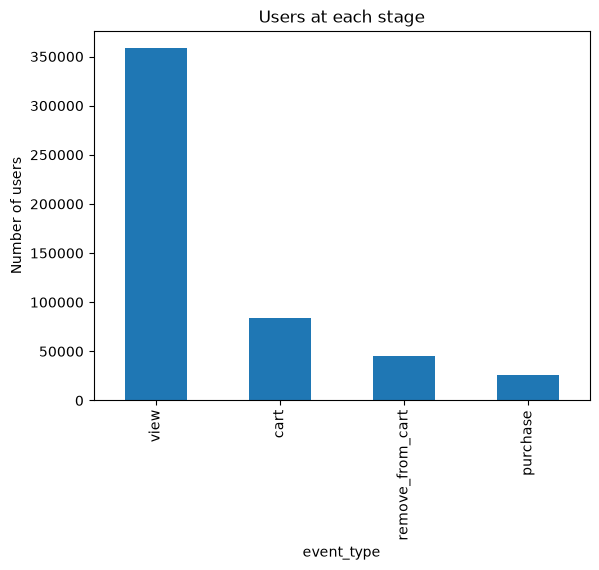

In [12]:
# how many events of each type
print(df["event_type"].value_counts())

# how many users reached each stage of the funnel
funnel = df.groupby("event_type")["user_id"].nunique()
print(funnel)

# share of viewers who ended up buying
buy_rate = funnel["purchase"] / funnel["view"]
print("Buy rate:", round(buy_rate * 100, 2), "%")

# plot the funnel
funnel.sort_values(ascending=False).plot(kind="bar")
plt.title("Users at each stage")
plt.ylabel("Number of users")
plt.show()

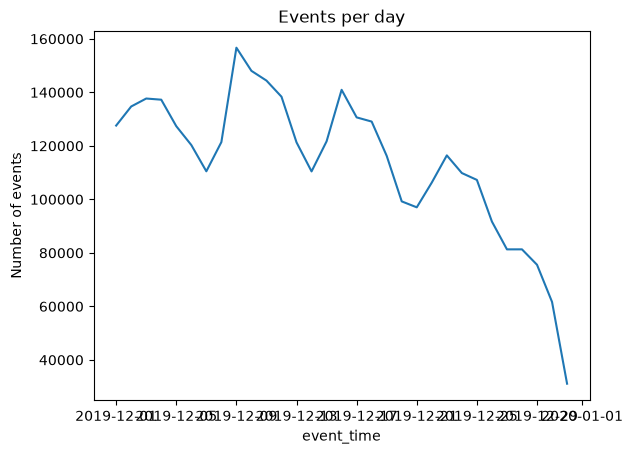

In [13]:
# count events per day to see activity over the month
daily = df.groupby(df["event_time"].dt.date).size()

# plot it to spot missing days or strange drops
daily.plot()
plt.title("Events per day")
plt.ylabel("Number of events")
plt.show()

### Check Data Quality

**What we do:** Study missing values, duplicates, and bad prices before removing anything.
**Why:** A problem can be a real error or real behavior, so we must understand it first.
**Why it matters:** Every cleaning decision in the next step is based on what we find here.

In [14]:
# missing values in each column (%)
print((df.isnull().mean() * 100).round(2))

# duplicates: compare their event types with the whole data
dups = df[df.duplicated()]
print(pd.DataFrame({"all": df["event_type"].value_counts(), "duplicates": dups["event_type"].value_counts()}))

# is a missing brand linked to cheaper products?
print(df.groupby(df["brand"].isnull())["price"].median())

# category_id can replace the empty category_code if it is complete
print("Missing category_id:", df["category_id"].isnull().sum())

# where zero and negative prices appear
print(df[df["price"] <= 0]["event_type"].value_counts())

event_time        0.00
event_type        0.00
product_id        0.00
category_id       0.00
category_code    98.35
brand            42.74
price             0.00
user_id           0.00
user_session      0.02
dtype: float64
                      all  duplicates
event_type                           
cart               927124       15483
purchase           213176         110
remove_from_cart   664655      168157
view              1728331         110
brand
False    4.22
True     4.17
Name: price, dtype: float64
Missing category_id: 0
event_type
view                6067
cart                1207
remove_from_cart     315
purchase              18
Name: count, dtype: int64


## Step 3: Cleaning

**What we do:** Apply cleaning decisions based on what we found in Step 2, then save the clean data.
**Why:** Each problem was studied first, so we only remove real errors and keep real behavior.
**Why it matters:** All later steps use this clean data, so every decision here is written down with its reason.

### Cleaning Decisions

| Problem | What we found | Decision | Why |
|---|---|---|---|
| Duplicate rows (183,860) | 91% are remove_from_cart; views and purchases have only 110 each | Remove | Likely one row per item removed in the same second. We count actions, not items. |
| Missing brand (42.7%) | Same median price with or without brand | Fill with "unknown" | Removing would lose 43% of the data. Missing brand is not linked to price. |
| Missing category_code (98.4%) | category_id has no missing values | Drop column | No information is lost, category_id holds the category for every row. |
| Missing user_session (0.02%) | Very few rows | Remove rows | Too few to affect results. |
| Zero or negative price (7,607) | Mostly views (6,067) | Keep row, blank the price | The event really happened, only the price is wrong. |

In [15]:
# count actions, not items: repeated rows in the same second are one action
df = df.drop_duplicates()

# category_id already holds the category, so this column adds nothing
df = df.drop(columns=["category_code"])

# keep rows with no brand as their own group
df["brand"] = df["brand"].fillna("unknown")

# too few rows with no session to matter
df = df.dropna(subset=["user_session"])

# the event is real but the price is wrong, so keep the row and blank the price
df.loc[df["price"] <= 0, "price"] = None

# check the result and save it
print(df.shape)
print(df.isnull().sum())
processed_path = data_path.replace("raw", "processed")
os.makedirs(processed_path, exist_ok=True)
df.to_pickle(processed_path + "2019-Dec-clean.pkl")

(3348712, 8)
event_time         0
event_type         0
product_id         0
category_id        0
brand              0
price           7537
user_id            0
user_session       0
dtype: int64


### Before vs After Cleaning

**What we do:** Compare event counts and prices before and after cleaning.
**Why:** Cleaning should remove errors without changing the real shape of the data.
**Why it matters:** If a chart changes a lot, we may have removed real behavior, not just errors.

           before       after
count  3533286.00  3341175.00
mean         8.87        9.10
std         19.86       20.27
min        -79.37        0.05
25%          2.06        2.14
50%          4.21        4.29
75%          7.14        7.17
max        327.78      327.78


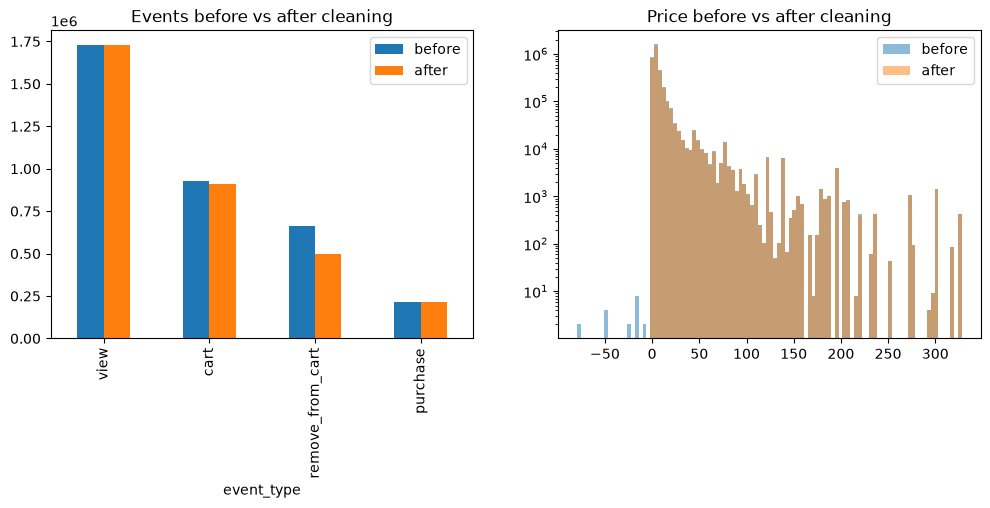

In [18]:
import matplotlib.pyplot as plt

# load only the two columns we need from the raw file
raw = pd.read_csv(data_path + "2019-Dec.csv", usecols=["event_type", "price"])

# compare the main price numbers
print(pd.DataFrame({"before": raw["price"].describe(), "after": df["price"].describe()}).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# events before and after cleaning
pd.DataFrame({"before": raw["event_type"].value_counts(), "after": df["event_type"].value_counts()}).plot(kind="bar", ax=axes[0])
axes[0].set_title("Events before vs after cleaning")

# same bins for both so the comparison is fair
price_range = (raw["price"].min(), raw["price"].max())
axes[1].hist(raw["price"], bins=100, range=price_range, alpha=0.5, label="before", log=True)
axes[1].hist(df["price"].dropna(), bins=100, range=price_range, alpha=0.5, label="after", log=True)
axes[1].set_title("Price before vs after cleaning")
axes[1].legend()

# save the chart for the README later
fig_path = data_path.replace("data/raw/", "reports/figures/")
os.makedirs(fig_path, exist_ok=True)
plt.savefig(fig_path + "before_after_cleaning.png", bbox_inches="tight")
plt.show()

### What I Learned from the Before/After Check

I don't trust a cleaning step until I see what it changed, so I compared the data before and after.

1. **The cleaning is safe.** Views and purchases did not change, and the price distribution looks the same. The only big drop was in remove_from_cart, which is exactly where the duplicates were. So I can trust every result that comes after this step.

2. **Price needs a log transform.** Most products cost under 20, but a few go up to about 330. For Logistic Regression I will use log(price). LightGBM can handle it as it is.

3. **There are limits I need to be honest about.** Remove events were logged once per item, and there is no quantity column. So I can count what customers did, but I can't measure revenue accurately. Also, about 7,600 prices are empty, so every price feature has to handle missing values.

4. **This check will become part of monitoring.** Every new month must go through the same cleaning. If duplicates suddenly jump from 5% to 20%, or negative prices come back, it means something changed in how the data is logged. I want to catch that before the model learns from broken data. That's why I will turn this cleaning into a function in `src/` later.

## Step 4: Exploratory Data Analysis

**What we do:** Answer three questions about buying behavior. 

**Why:** Each answer decides something later: which features to build, which timing features to add, and how long the prediction window should be.

**Why it matters:** EDA gives us ideas to test. The model and SHAP will later confirm which ones really matter.

### Q1: How are buyers different from non-buyers?

Do buyers view more products? Do they use the cart more? Do they remove items from the cart less? 

**This decides:** which behavior features I build for the model.

In [19]:
# count each action per user
users = df.pivot_table(index="user_id", columns="event_type", values="product_id", aggfunc="count", fill_value=0)
users["buyer"] = users["purchase"] > 0

# compare buyers and non-buyers
print(users.groupby("buyer")[["view", "cart", "remove_from_cart"]].median())
print(users["buyer"].value_counts())

event_type  view  cart  remove_from_cart
buyer                                   
False        1.0   0.0               0.0
True         9.0   9.0               3.0
buyer
False    344495
True      25613
Name: count, dtype: int64


**Answer:** Buyers and non-buyers behave very differently. The typical non-buyer viewed one product and left, with no cart activity at all. The typical buyer viewed 9 products, added 9 to the cart, and removed 3.

What surprised me is that buyers remove items from the cart *more*, not less. I expected removing to be a sign of hesitation, but it looks more like active shopping: people who are serious about buying edit their cart.

Since most non-buyers are one-time visitors, telling them apart from buyers is easy. The real challenge for the model is the users who *are* engaged: among people who use the cart, who actually buys? This shapes the features I build.

*Note: these are totals for the whole month, including actions after the purchase. For the model, I will only use actions that happened before the prediction time, to avoid leakage.*

### Q2: When do people buy?

Is the buy rate higher at certain hours or on certain days of the week? I use rates, not counts, because more visitors at a certain hour does not mean more buying.

**This decides:** whether hour and weekday are worth adding as features.

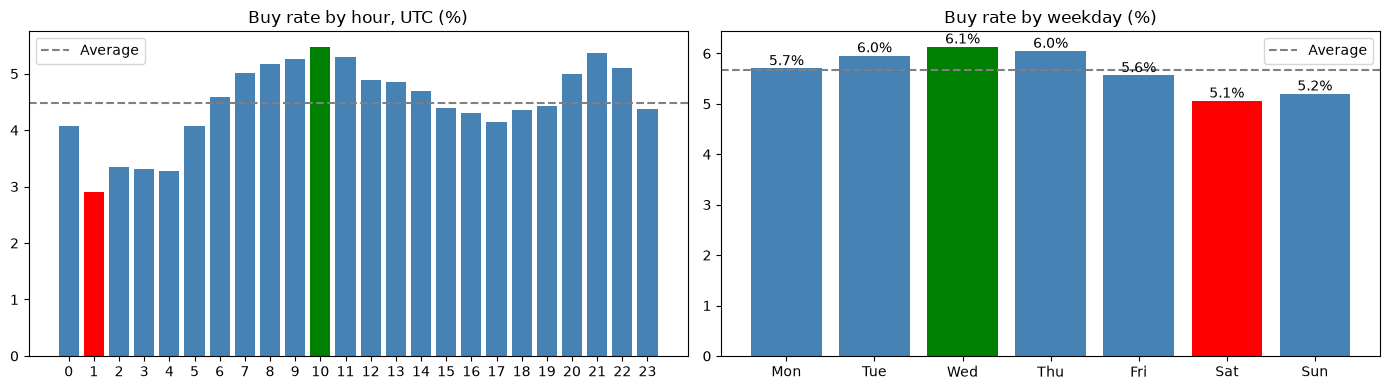

In [36]:
df["hour"] = df["event_time"].dt.hour
df["weekday"] = df["event_time"].dt.dayofweek
purchases = df[df["event_type"] == "purchase"]

# buy rate = users who bought / users who were active
by_hour = purchases.groupby("hour")["user_id"].nunique() / df.groupby("hour")["user_id"].nunique() * 100
by_day = purchases.groupby("weekday")["user_id"].nunique() / df.groupby("weekday")["user_id"].nunique() * 100
by_day.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, data, title in zip(axes, [by_hour, by_day], ["Buy rate by hour, UTC (%)", "Buy rate by weekday (%)"]):
    # best bar in green, worst in red, the rest in blue
    colors = ["green" if v == data.max() else "red" if v == data.min() else "steelblue" for v in data]
    ax.bar(data.index.astype(str), data, color=colors)
    # dashed line for the average
    ax.axhline(data.mean(), color="gray", linestyle="--", label="Average")
    ax.set_title(title)
    ax.legend()

# show the value on each weekday bar
for i, v in enumerate(by_day):
    axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom")

# save the chart for the README
plt.tight_layout()
plt.savefig(fig_path + "buy_rate_hour_weekday.png", bbox_inches="tight")
plt.show()

**Answer:** Hour matters a lot. The buy rate goes from about 2.9% at its lowest (1:00) to about 5.5% at its highest (10:00), almost double. There are two peaks: late morning and evening. So hour is worth adding as a feature.

Weekday matters less. Midweek (Tuesday to Thursday) has the highest rate, about 6.1%, and the weekend has the lowest, about 5.1%. People visit on weekends but buy less. I will add weekday too, but I expect it to be a weaker signal than hour.

*Note: hours are in UTC, not the store's local time, so I read the overall shape, not the exact hour. Also, this is only December, which includes Christmas and New Year, so I will check these patterns again when I add more months.*

### Q3: How long does it take to go from first view to purchase?

Do most buyers decide in minutes, in hours, or over several days?

**This decides:** how long the prediction window should be (for example, "will this user buy in the next 7 days?").

In [21]:
# time from each buyer's first view to first purchase, in hours
first_view = df[df["event_type"] == "view"].groupby("user_id")["event_time"].min()
first_buy = df[df["event_type"] == "purchase"].groupby("user_id")["event_time"].min()
hours = (first_buy - first_view).dropna().dt.total_seconds() / 3600
hours = hours[hours >= 0]

print(hours.describe().round(1))
print("Bought within 1 day:", round((hours <= 24).mean() * 100, 1), "%")
print("Bought within 7 days:", round((hours <= 168).mean() * 100, 1), "%")

count    23375.0
mean        69.7
std        127.2
min          0.0
25%          0.3
50%          2.3
75%         76.6
max        718.1
Name: event_time, dtype: float64
Bought within 1 day: 64.1 %
Bought within 7 days: 84.0 %


**Answer:** Buyers fall into two groups. Fast deciders: half of buyers purchase within about 2 hours of their first view, and a quarter within 18 minutes. Slow deciders: a quarter take more than 3 days, and some take up to a month. Overall, 64% buy within 1 day and 84% within 7 days.

Because of these two groups, the average (about 70 hours) is misleading. The median (2.3 hours) describes the typical buyer much better.

**My decision:** I will use a 7-day prediction window ("will this user buy in the next 7 days?"). It covers 84% of buyers and still gives the business time to act, for example by sending a reminder. The long tail of slow buyers is also why I will use survival analysis for the "when" question: it handles people who haven't bought *yet* better than a simple yes/no model.

*Note: I only see December. A user who started browsing in November looks like a fast buyer, and a user who will buy in January looks like a non-buyer. Both make decisions look faster than they really are, so I will check this again with more months.*

### Q4: Among cart users, what separates buyers from non-buyers?

70% of people who add to the cart never buy. This is where the real business problem is.

**This decides:** the features that matter most, because separating engaged users is the hard part of the model.

In [22]:
# keep only users who used the cart
cart_only = users[users["cart"] > 0]

# compare cart users who bought with those who didn't
print(cart_only.groupby("buyer")[["view", "cart", "remove_from_cart"]].median())
print(cart_only["buyer"].value_counts(normalize=True).round(3))

event_type  view  cart  remove_from_cart
buyer                                   
False        3.0   3.0               0.0
True         9.0  10.0               3.0
buyer
False    0.697
True     0.303
Name: proportion, dtype: float64


**Answer:** Even among cart users, buyers are about three times more active. The typical buyer viewed 9 products, added 10 to the cart, and removed 3. The typical cart user who did not buy viewed 3, added 3, and removed nothing.

This tells a clear story: people who abandon their cart add a few items and leave. People who buy spend time shaping their cart. Cart activity, especially removing items, is the strongest sign of real buying intent.

### Q5: Do buyers come back in more than one session before buying?

**This decides:** whether the number of visits is worth adding as a feature.

In [23]:
# number of separate visits per user
users["sessions"] = df.groupby("user_id")["user_session"].nunique()

print(users.groupby("buyer")["sessions"].median())
print(users[users["cart"] > 0].groupby("buyer")["sessions"].median())

buyer
False    1.0
True     3.0
Name: sessions, dtype: float64
buyer
False    2.0
True     3.0
Name: sessions, dtype: float64


**Answer:** Buyers come back more: 3 visits for the typical buyer versus 1 for non-buyers. Among cart users, the gap is smaller (3 versus 2), but still there. I will add the number of visits as a feature.

*Note: buyers always have at least one visit with a purchase, so part of this gap is built in. For the model, I will only count visits before the prediction time.*

### Q6: Does price affect buying?

**This decides:** whether to build price features, and if they need a log transform.

In [24]:
# average price of the products each user viewed
users["avg_price"] = df[df["event_type"] == "view"].groupby("user_id")["price"].mean()

print(users.groupby("buyer")["avg_price"].median().round(2))

buyer
False    6.54
True     6.50
Name: avg_price, dtype: float64


**Answer:** No. Buyers and non-buyers look at products with almost the same average price (6.50 versus 6.54), and the correlation with buying is close to zero. Price is not a strong signal in this store, probably because most products are cheap cosmetics.

**My decision:** I will not spend effort on price features. I will keep one simple price feature only so the model can confirm this.

### How do these behaviors relate to each other?

I use Spearman correlation because the counts are very skewed: most users view one product, and a few view hundreds. 

**This decides:** which features repeat each other, and which ones look most linked to buying.

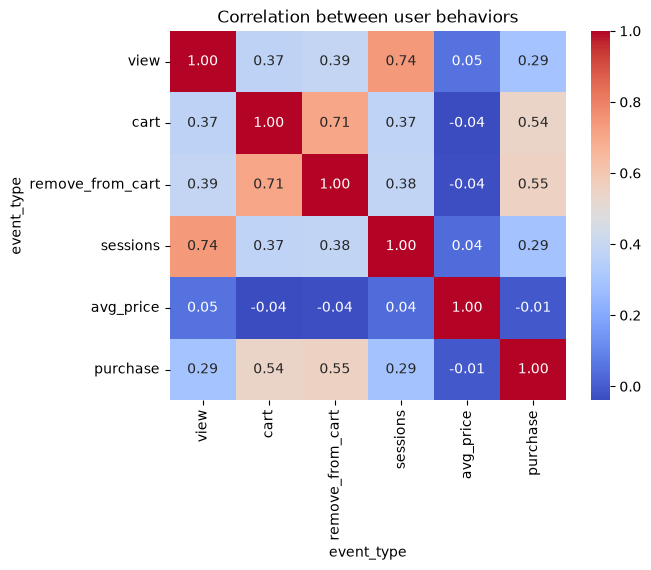

In [25]:
import seaborn as sns

# how strongly each pair of behaviors moves together
corr = users[["view", "cart", "remove_from_cart", "sessions", "avg_price", "purchase"]].corr(method="spearman")

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between user behaviors")
plt.show()

**Answer:** Two pairs repeat each other: views and visits (0.74), and cart and remove (0.71). This makes sense: more visits means more views, and more items in the cart means more chances to remove some.

Cart and remove are the most linked to buying (0.54 and 0.55), then views and visits (0.29). Price is not linked at all.

**My decision:** LightGBM can handle features that repeat each other, so I keep them all for it. For Logistic Regression, I will replace each pair with a ratio, such as views per visit and removes per cart item, so the model doesn't get confused by two features saying the same thing.

*Note: these numbers use full-month totals, including actions after buying, so they look stronger than they really are. The time-based split will show the true strength.*

### Q7: How does buying change across December, and what did the holidays affect?

Sales = visitors × share who buy × basket value. A weak period can come from fewer visitors, fewer buyers among them, or smaller baskets, and each one needs a different fix. 

**This decides:** whether holidays need special handling in the model, and which cutoff date gives a normal week to test on.

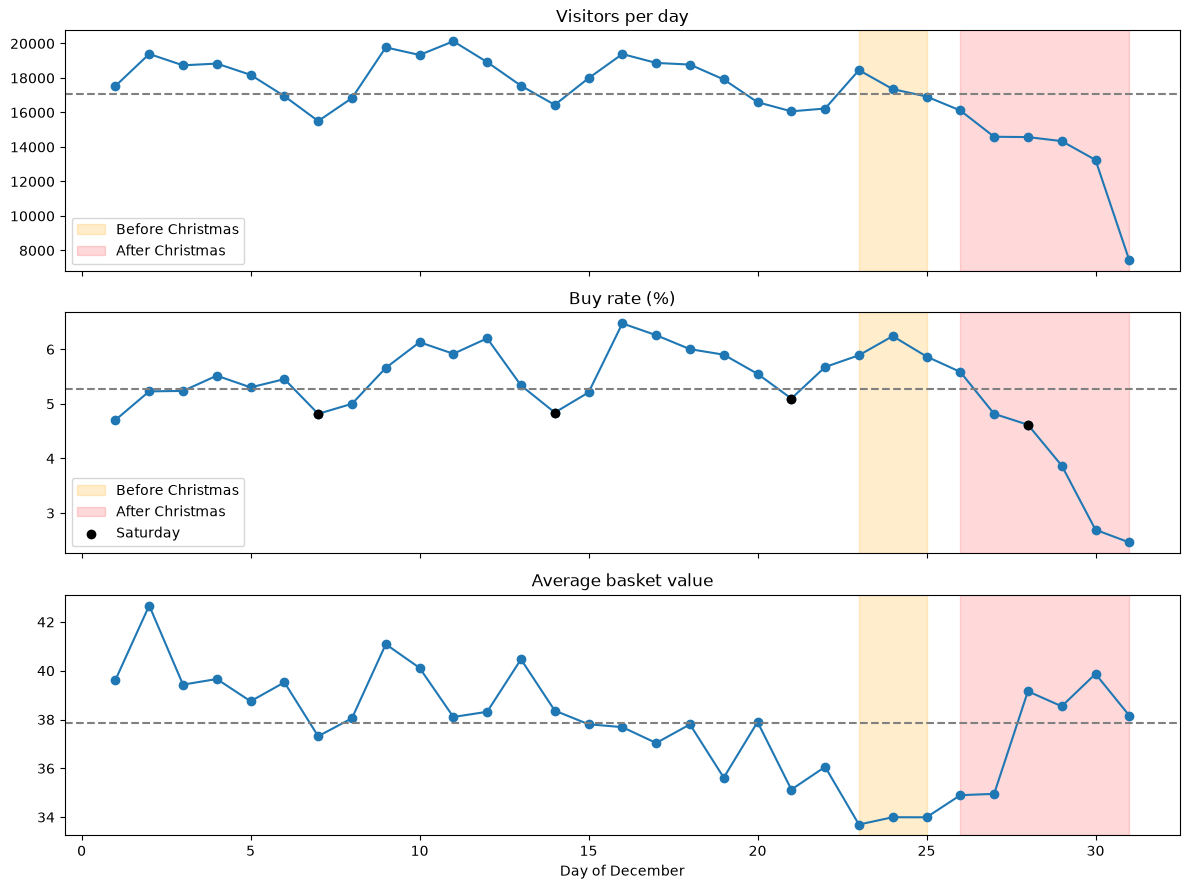

In [35]:
df["date"] = df["event_time"].dt.date
purchases = df[df["event_type"] == "purchase"]

# the three parts of sales for each day
daily = pd.DataFrame({
    "visitors": df.groupby("date")["user_id"].nunique(),
    "buyers": purchases.groupby("date")["user_id"].nunique(),
    "basket": purchases.groupby(["date", "user_id"])["price"].sum().groupby("date").mean()
})
daily["buy_rate"] = daily["buyers"] / daily["visitors"] * 100

# use the day of the month on the x-axis so it's easy to read
daily.index = pd.to_datetime(daily.index).day

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
parts = ["visitors", "buy_rate", "basket"]
titles = ["Visitors per day", "Buy rate (%)", "Average basket value"]

for ax, col, title in zip(axes, parts, titles):
    ax.plot(daily.index, daily[col], marker="o")
    # dashed line for the month average
    ax.axhline(daily[col].mean(), color="gray", linestyle="--")
    # shade the two holiday periods
    ax.axvspan(23, 25, color="orange", alpha=0.2, label="Before Christmas")
    ax.axvspan(26, 31, color="red", alpha=0.15, label="After Christmas")
    ax.set_title(title)

# mark Saturdays on the buy rate chart
saturdays = [7, 14, 21, 28]
axes[1].scatter(saturdays, daily.loc[saturdays, "buy_rate"], color="black", zorder=3, label="Saturday")

axes[0].legend(loc="lower left")
axes[1].legend(loc="lower left")
axes[2].set_xlabel("Day of December")

# save the chart for the README
plt.tight_layout()
plt.savefig(fig_path + "december_daily.png", bbox_inches="tight")
plt.show()

**Answer:** December has three different periods, and each one is weak in a different part of sales:

- **Normal weeks (Dec 1–22):** steady visitors and a buy rate of 5–6.5%. Saturdays are always the weakest day for buying.
- **Before Christmas (Dec 23–25):** the buy rate stays high, but baskets are the smallest of the month (about 34 vs about 40 early in the month). Many people buy, but they buy small, probably last-minute gifts.
- **After Christmas (Dec 26–31):** both visitors and the buy rate drop. By Dec 31, the buy rate falls to about 2.5%, less than half of normal. The few people who still buy have bigger baskets.

**What a business could do with this:**
- Before Christmas, the problem is basket size, not buyers, so bundles or "add one more" offers make sense.
- After Christmas, the problem is that people stop buying, so this is where targeted reminders to users most likely to buy would help. This is exactly what the model is for.
- On Saturdays, people visit but buy less, which makes weekends a good time to test offers.

**My decision for the model:** the last week of December is not normal behavior, and I only have one Christmas in the data, so the model can't learn holiday effects from a single example. I keep the cutoff at Dec 15, so the target week (Dec 15–21) is a normal week.

*Note: this is one month, so these are patterns to test, not proven causes. Basket value is approximate because there is no quantity column.*

### Q8: How long do items stay in the cart before people buy?

Do buyers check out right after adding to the cart, or do they leave it and come back later? 

**This decides:** the best time to send a cart reminder, and it supports the survival model for the "when" question.

In [27]:
# time from each buyer's first cart to first purchase, in hours
first_cart = df[df["event_type"] == "cart"].groupby("user_id")["event_time"].min()
cart_hours = (first_buy - first_cart).dropna().dt.total_seconds() / 3600
cart_hours = cart_hours[cart_hours >= 0]

print(cart_hours.describe().round(1))
print("Bought within 1 hour of first cart:", round((cart_hours <= 1).mean() * 100, 1), "%")
print("Bought within 1 day of first cart:", round((cart_hours <= 24).mean() * 100, 1), "%")

count    25185.0
mean        45.1
std        101.4
min          0.0
25%          0.2
50%          0.8
75%         25.9
max        714.3
Name: event_time, dtype: float64
Bought within 1 hour of first cart: 52.3 %
Bought within 1 day of first cart: 74.1 %


**Answer:** Half of buyers check out within an hour of their first cart (median about 48 minutes), and a quarter within 12 minutes. By the end of the first day, 74% of buyers have bought. Only a quarter of buyers take longer than a day.

This shows a clear window. If someone adds to the cart and doesn't buy within about an hour, their chance drops. After a day, it drops a lot more.

**What a business could do with this:** send a cart reminder about one hour after someone leaves without buying. That's after most people who were going to buy anyway have done it, but still early enough to catch the ones who might come back.

**My decision for the model:** add a feature for time since the user's last cart action, because how recently someone used the cart clearly matters.

### Q9: Do buyers come back and buy again?

Do most buyers purchase once, or do they return on other days to buy more?  

**This decides:** whether past purchases are worth adding as a feature.

In [28]:
# on how many different days did each buyer purchase?
buy_days = purchases.groupby("user_id")["date"].nunique()

print(buy_days.value_counts().sort_index().head(10))
print("Bought on more than one day:", round((buy_days > 1).mean() * 100, 1), "%")

date
1     23386
2      1830
3       283
4        70
5        18
6         8
7         7
8         2
9         1
10        2
Name: count, dtype: int64
Bought on more than one day: 8.7 %


### Q10: Do some brands turn viewers into buyers more than others?

Is the buy rate very different between brands? And what about products with no brand ("unknown")? 

**This decides:** whether brand is worth adding as a feature.

In [29]:
# buy rate by brand: users who bought it / users who viewed it
brand_view = df[df["event_type"] == "view"].groupby("brand")["user_id"].nunique()
brand_buy = purchases.groupby("brand")["user_id"].nunique()
brand_rate = (brand_buy / brand_view * 100).dropna()

# keep brands with at least 1,000 viewers so the rate means something
top = brand_view[brand_view >= 1000].index
print("Highest buy rate:")
print(brand_rate[top].sort_values(ascending=False).head(10).round(1))
print("\nLowest buy rate:")
print(brand_rate[top].sort_values().head(10).round(1))
print("\nUnknown brand:", round(brand_rate["unknown"], 1))

Highest buy rate:
brand
severina     50.6
smart        31.0
swarovski    29.3
de.lux       24.7
bpw.style    24.3
dartnails    24.1
domix        23.2
freedecor    22.9
farmstay     22.2
milv         21.5
Name: user_id, dtype: float64

Lowest buy rate:
brand
kosmekka     0.3
strong       2.5
marathon     3.0
sunuv        3.3
shik         4.4
missha       4.4
farmavita    4.6
kaypro       4.9
emil         5.3
jas          5.3
Name: user_id, dtype: float64

Unknown brand: 11.3


**Answer:** Brands make a big difference. Among brands with at least 1,000 viewers, the buy rate goes from 0.3% to 50.6%. Some brands turn viewers into buyers much more than others.

What surprised me: products with no brand ("unknown") have a buy rate of 11.3%, which is higher than average. In cleaning, I found missing brand was not linked to price. Now I see it *is* linked to buying. This confirms that filling it with "unknown" instead of deleting those rows was the right choice.

**My decision for the model:** there are too many brands to use one by one, so I will add one feature: the average buy rate of the brands each user looked at. I will calculate these brand rates from the history period only, before the cutoff. If I used the whole month, the feature would include information from the target week, and that would be leakage.

*Note: very high rates like 50.6% may come from products people buy again and again (like professional supplies), so I treat these numbers as patterns, not facts.*

### Q11: Which months have the highest sales, and why?

Comparing October to February (Black Friday, Christmas, after the holidays, Valentine's Day), split into visitors, buy rate, and basket value.

**This decides:** whether month or events need special handling, and which months to use for training, testing, and monitoring.



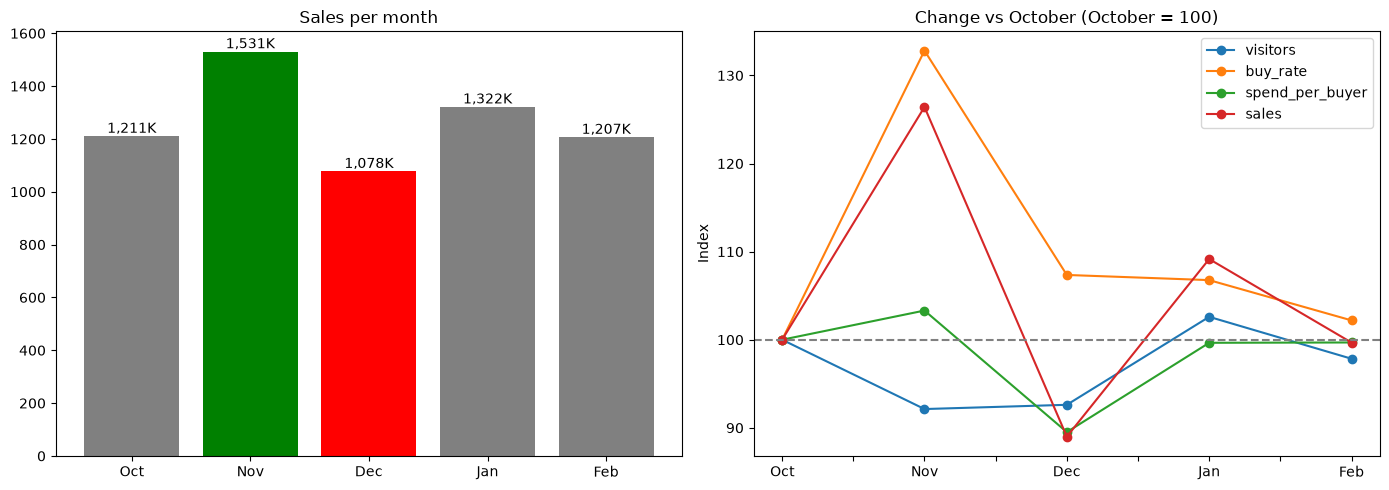

In [34]:
cols = ["visitors", "buy_rate", "spend_per_buyer", "sales"]

# show each part as a % of October so they all fit on one chart
index = monthly[cols] / monthly[cols].iloc[0] * 100
index.index = ["Oct", "Nov", "Dec", "Jan", "Feb"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left: sales per month, best month in green and weakest in red
sales_k = monthly["sales"].values / 1000
colors = ["gray", "green", "red", "gray", "gray"]
axes[0].bar(index.index, sales_k, color=colors)
for i, v in enumerate(sales_k):
    axes[0].text(i, v, f"{v:,.0f}K", ha="center", va="bottom")
axes[0].set_title("Sales per month")

# right: what changed compared with October
index.plot(ax=axes[1], marker="o")
axes[1].axhline(100, color="gray", linestyle="--")
axes[1].set_title("Change vs October (October = 100)")
axes[1].set_ylabel("Index")

# save the chart for the README
plt.tight_layout()
plt.savefig(fig_path + "monthly_comparison.png", bbox_inches="tight")
plt.show()

**Answer:** Visitors stay almost the same every month (about 370K to 410K). So the differences in sales don't come from how many people visit. They come from how many of them buy, and how much they spend.

- **November is the best month** (about 1.5M in sales), but not because of more visitors. It actually had fewer visitors than October. What changed is the buy rate, which jumped from about 6.4% to about 8.6%. Black Friday didn't bring new people; it made the people who already visit buy more.
- **December is the weakest month** (about 1.08M), mainly because each buyer spent less (about 42 vs about 47 in other months). This matches Q7: small baskets before Christmas, then a sharp drop after it.
- **January surprised me.** I expected a slow month after the holidays, but it was the second-best month, with the most visitors.
- **October and February** are normal months, with similar sales (about 1.2M).

**What a business could do with this:** since visitors are stable, the biggest lever is turning more visitors into buyers, not bringing more people in. November shows the buy rate can rise by about a third without any extra traffic. In weaker months, the goal should be to get closer to that, for example by targeting users most likely to buy, which is exactly what the model does. In December, the problem is basket size, so bundles fit better than discounts.

**My decision for the model:** November behaves very differently from the other months. I will test the model on February, a normal and the most recent month. November will be a good test for monitoring: if the model is trained on normal months, its performance should change when behavior changes like this.

*Note: this shows what happened, not why. Black Friday is the likely reason for November, but only a test would prove it. Sales are approximate because there is no quantity column.*

### EDA Conclusions → Decisions

**The story:** Most visitors look at one product and leave. The real problem is the cart: 70% of people who add to the cart never buy. Buyers are about three times more active, come back more often, and spend time shaping their cart. Price doesn't separate them, but brand and timing do. Half of buyers check out within an hour of their first cart, and 84% buy within 7 days. Across five months, visitors stay stable, so sales go up or down because of how many people buy and how much they spend, not because of traffic. November proves the buy rate can rise by a third without more visitors.

| Question | What I found | What I will do |
|---|---|---|
| Q1 | Most non-buyers view one product and leave | Focus the model on engaged users, where the real challenge is. |
| Q4 | 70% of cart users don't buy; buyers are 3x more active and shape their cart | Cart and remove counts are the core features. The story: who completes an abandoned cart? |
| Q1, Q4 | Buyers remove items more, not less | Keep remove count as a sign of active shopping. |
| Q5 | Buyers come back more often (3 visits vs 1) | Add number of visits as a feature. |
| Q9 | Only 8.7% of buyers buy again on another day | Keep past purchases as a feature, but expect it to be weak. |
| Q6 | Price does not separate buyers from non-buyers | Keep only one simple price feature. |
| Q10 | Brands differ a lot (0.3% to 50.6%); "unknown" brand is above average | Add the average buy rate of the brands each user viewed, from the history period only. |
| Correlation | Views and visits repeat each other; so do cart and remove | Keep all for LightGBM; use ratios for Logistic Regression. |
| Q2 | Buy rate almost doubles between the lowest and highest hours | Add hour of activity as a feature. |
| Q2, Q7 | Midweek is higher than the weekend; Saturday is always the lowest | Add weekday as a weaker feature. |
| Q8 | Half of buyers check out within an hour of their first cart | Add time since last cart; a reminder after about an hour makes business sense. |
| Q3 | 84% of buyers buy within 7 days | Use a 7-day prediction window. |
| Q3 | Two groups: fast and slow deciders | Use survival analysis for the "when" question. |
| Q11 | Visitors are stable across months; sales change with buy rate and spend | The main business lever is conversion, which is what the model targets. |
| Q11 | November has a much higher buy rate (Black Friday) | Test on February (a normal month); use November to check monitoring. |
| Q7, Q11 | December has the smallest baskets; after Christmas everything drops | Keep target weeks away from the holidays (cutoff on day 15). |
| Q7 | Only one holiday season in the data | Don't try to learn holiday effects from one example. |

## Step 5: Feature Engineering

**What we do:** For each month, take a cutoff on day 15. Use the 14 days before it to build one row of features per user, and label whether they bought in the 7 days after it.
**Why:** The model must only see the past, exactly like a real prediction made today about next week. Using the same 14-day history for every month makes the features mean the same thing everywhere.
**Why it matters:** October and December are for training, January for validation, February for the final test (touched only once), and November is kept for monitoring because Black Friday changes behavior.

| Feature | What it means | Why (from EDA) |
|---|---|---|
| view, cart, remove_from_cart | How many times the user did each action | Buyers are about 3x more active (Q1, Q4) |
| past_purchases | Purchases in the history period | Repeat buying is rare, so expected to be weak (Q9) |
| sessions | Number of separate visits | Buyers come back more often (Q5) |
| days_since_last, days_since_first | Days from last and first activity to the cutoff | How recent and how long the user has been around |
| days_since_last_cart | Days from the last cart action to the cutoff | Most buyers check out soon after the cart (Q8) |
| avg_price | Average price of products seen | Kept only to confirm price is weak (Q6) |
| avg_brand_rate | Average buy rate of the brands the user viewed, from the history only | Brands differ a lot (Q10) |
| last_hour, last_weekday | When the user was last active | Buy rate changes by hour and weekday (Q2) |
| views_per_session, remove_per_cart | Ratios | Replace pairs that repeat each other, for Logistic Regression |

## Target Definition

**Question:** Among users with cart activity, who will buy in the next 7 days?

- **Unit (one row):** one user at one cutoff date, only users with cart activity in the 14 days before the cutoff.
- **Prediction moment:** day 15 of each month at 00:00.
- **Allowed information:** only events in the 14 days before the cutoff. Nothing after it.
- **Target:** 1 if the user makes any purchase in the 7 days after the cutoff, 0 if not.

**Why this question:** 70% of cart users never buy (Q4), so this is where the business loses money. **Why 7 days:** 84% of buyers buy within 7 days (Q3). A same-session target would miss the quarter of buyers who come back after more than a day (Q8).

In [37]:
def clean_month(path):
    d = pd.read_csv(path)
    d["event_time"] = pd.to_datetime(d["event_time"].str.replace(" UTC", ""))

    # same cleaning decisions as Step 3
    d = d.drop_duplicates()
    d = d.drop(columns=["category_code"])
    d["brand"] = d["brand"].fillna("unknown")
    d = d.dropna(subset=["user_session"])
    d.loc[d["price"] <= 0, "price"] = None
    return d


def build_features(d, cutoff, history_days=14, target_days=7):
    cutoff = pd.Timestamp(cutoff)

    # the 14 days before the cutoff, and the 7 days after it
    past = d[(d["event_time"] >= cutoff - pd.Timedelta(days=history_days)) & (d["event_time"] < cutoff)]
    future = d[(d["event_time"] >= cutoff) & (d["event_time"] < cutoff + pd.Timedelta(days=target_days))]

    # count each action per user
    feats = past.pivot_table(index="user_id", columns="event_type", values="product_id", aggfunc="count", fill_value=0)
    feats = feats.rename(columns={"purchase": "past_purchases"})

    # visits and timing
    first_time = past.groupby("user_id")["event_time"].min()
    last_time = past.groupby("user_id")["event_time"].max()
    last_cart = past[past["event_type"] == "cart"].groupby("user_id")["event_time"].max()
    feats["sessions"] = past.groupby("user_id")["user_session"].nunique()
    feats["days_since_last"] = (cutoff - last_time).dt.total_seconds() / 86400
    feats["days_since_first"] = (cutoff - first_time).dt.total_seconds() / 86400

    # users with no cart get the full window length
    feats["days_since_last_cart"] = ((cutoff - last_cart).dt.total_seconds() / 86400).reindex(feats.index).fillna(history_days)
    feats["avg_price"] = past.groupby("user_id")["price"].mean()
    feats["last_hour"] = last_time.dt.hour
    feats["last_weekday"] = last_time.dt.dayofweek

    # brand buy rate from the history only, then the average for each user
    views = past[past["event_type"] == "view"]
    brand_rate = (past[past["event_type"] == "purchase"].groupby("brand")["user_id"].nunique() / views.groupby("brand")["user_id"].nunique()).fillna(0)
    seen = views[["user_id", "brand"]].drop_duplicates()
    seen["brand_rate"] = seen["brand"].map(brand_rate)
    feats["avg_brand_rate"] = seen.groupby("user_id")["brand_rate"].mean()

    # ratios so logistic regression doesn't see the same thing twice
    feats["views_per_session"] = feats["view"] / feats["sessions"]
    feats["remove_per_cart"] = feats["remove_from_cart"] / feats["cart"].replace(0, 1)

    # target: did the user buy in the next 7 days?
    buyers = future[future["event_type"] == "purchase"]["user_id"].unique()
    feats["target"] = feats.index.isin(buyers).astype(int)
    feats["cutoff"] = cutoff
    return feats

In [38]:
# free the December data we used in EDA to save memory
del df

cutoffs = {"2019-Oct": "2019-10-15", "2019-Dec": "2019-12-15", "2020-Jan": "2020-01-15", "2020-Feb": "2020-02-15"}
all_feats = []

# one month at a time so memory stays low
for m, c in cutoffs.items():
    d = clean_month(data_path + m + ".csv")
    all_feats.append(build_features(d, c))
    print(m, "done")

features = pd.concat(all_feats).reset_index()

# share of users who bought in each target week
print(features.groupby("cutoff")["target"].mean().round(3))
print(features.shape)

# save so the next steps can start from here
features.to_pickle(processed_path + "features_all.pkl")
features.head()

2019-Oct done
2019-Dec done
2020-Jan done
2020-Feb done
cutoff
2019-10-15    0.012
2019-12-15    0.015
2020-01-15    0.014
2020-02-15    0.013
Name: target, dtype: float64
(826481, 17)


event_type,user_id,cart,past_purchases,remove_from_cart,view,sessions,days_since_last,days_since_first,days_since_last_cart,avg_price,last_hour,last_weekday,avg_brand_rate,views_per_session,remove_per_cart,target,cutoff
0,8846226,24,0,12,7,2,12.382905,13.124838,12.388275,4.205116,14,2,0.093134,3.5,0.500000,0,2019-10-15
1,9794320,13,0,4,2,1,13.691794,13.747593,13.691794,1.312632,7,1,0.192047,2.0,0.307692,0,2019-10-15
2,13383118,0,0,0,1,1,2.307199,2.307199,14.000000,8.890000,16,5,0.168162,1.0,0.000000,0,2019-10-15
3,13392135,0,0,0,1,1,12.678611,12.678611,14.000000,1.730000,7,2,0.092045,1.0,0.000000,0,2019-10-15
4,14081087,0,0,0,1,1,0.270116,0.270116,14.000000,2.980000,17,0,0.093895,1.0,0.000000,0,2019-10-15


## Step 6: Time Split, Leakage Check & Outliers

**What we do:** Keep only users with cart activity, split by time, check that no feature uses events after the cutoff, then measure outliers on the training data only.
**Why:** Anything that learns from the data must come after the split, so the model never sees the validation or test months.
**Why it matters:** February stays untouched until the very end, and the outlier limits we choose here will be used in preprocessing.

**Why a time split:** in real use, the model predicts the future from the past, so the test must work the same way. November is left out because Black Friday changes behavior a lot; I keep it for monitoring. October and December are for training, January for comparing models and tuning, and February for the final test, used only once.

In [40]:
features = pd.read_pickle(processed_path + "features_all.pkl")

# keep only users with cart activity, where the real problem is
data = features[features["cart"] > 0]

# split by time
train = data[data["cutoff"] < "2020-01-01"]
valid = data[data["cutoff"] == "2020-01-15"]
test = data[data["cutoff"] == "2020-02-15"]

# check the size and buy rate of each part
for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(name, part.shape, "buy rate:", round(part["target"].mean() * 100, 1), "%")

train (138066, 17) buy rate: 3.0 %
valid (43466, 17) buy rate: 5.0 %
test (50392, 17) buy rate: 4.3 %


In [41]:
# no feature should use events after the cutoff or before the 14-day window
print("Events after cutoff:", (features["days_since_last"] < 0).sum())
print("Events before the window:", (features["days_since_first"] > 14).sum())

Events after cutoff: 0
Events before the window: 0


                   50%   95%   99%     max
event_type                                
view               1.0  35.0  93.0  6218.0
cart               3.0  30.0  70.0  1471.0
remove_from_cart   0.0  19.0  54.0  1879.0
past_purchases     0.0  10.0  24.0   366.0
sessions           1.0   9.0  28.0  5343.0
avg_price          5.2  24.5  64.3   327.8
views_per_session  1.0  10.0  25.0   374.0
remove_per_cart    0.0   1.2   3.5   568.0

Users above the top 1%:
event_type
view                 1370
cart                 1378
remove_from_cart     1357
past_purchases       1380
sessions             1365
avg_price            1377
views_per_session    1321
remove_per_cart      1316
dtype: int64


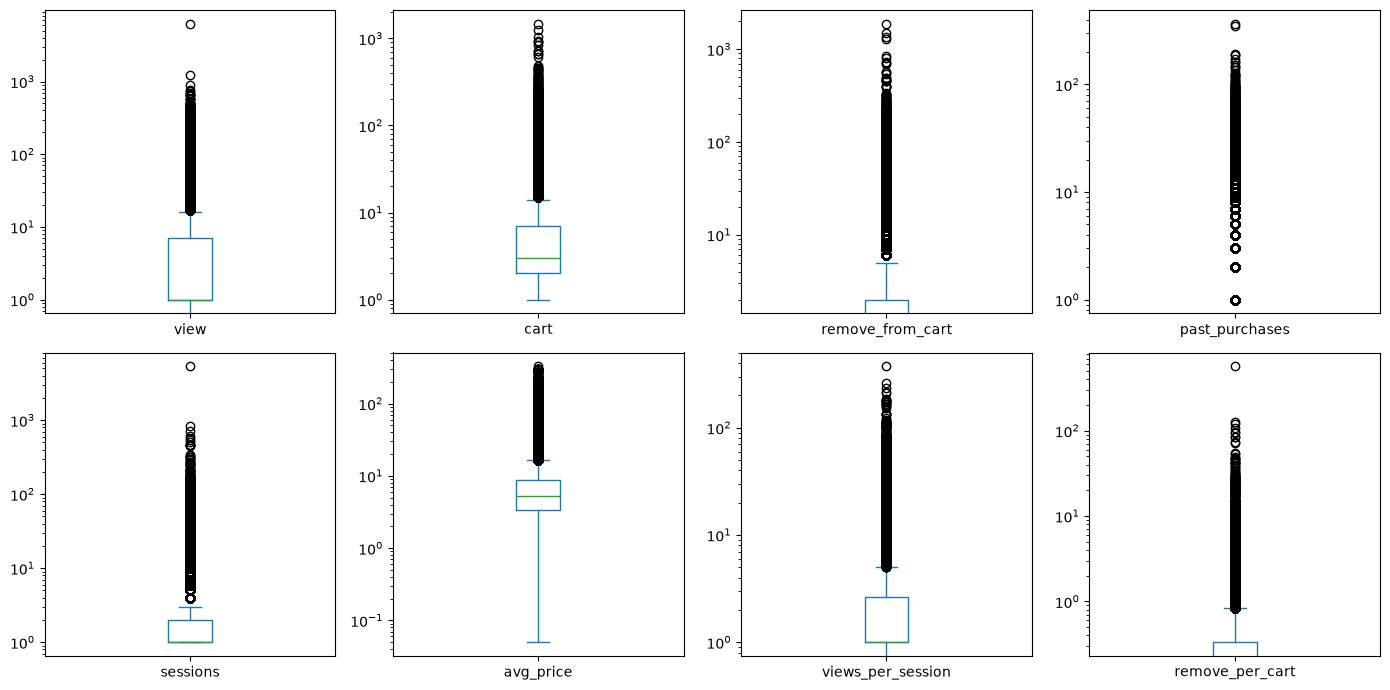

In [42]:
num_cols = ["view", "cart", "remove_from_cart", "past_purchases", "sessions",
            "avg_price", "views_per_session", "remove_per_cart"]

# compare the typical value, the top 5%, the top 1%, and the maximum
print(train[num_cols].describe(percentiles=[0.5, 0.95, 0.99]).T[["50%", "95%", "99%", "max"]].round(1))

# how many users are above the top 1% for each feature
top1 = train[num_cols].quantile(0.99)
print("\nUsers above the top 1%:")
print((train[num_cols] > top1).sum())

# box plots on a log scale because the counts are very skewed
train[num_cols].plot(kind="box", subplots=True, layout=(2, 4), figsize=(14, 7), logy=True)
plt.tight_layout()
plt.show()

### Are the extreme values real or errors?

Before deciding anything, I check the most extreme users in their raw events. A human doesn't stay active all 24 hours, doesn't act every few seconds without a break, and doesn't open a new visit for almost every click. A real heavy customer, on the other hand, buys things and shops at normal hours.

In [43]:
cols = ["user_id", "cutoff", "view", "cart", "remove_from_cart", "past_purchases", "sessions", "target"]

# the most extreme users by visits, views, and purchases
print("Most visits:")
print(train.sort_values("sessions", ascending=False)[cols].head(5))
print("\nMost views:")
print(train.sort_values("view", ascending=False)[cols].head(5))
print("\nMost purchases:")
print(train.sort_values("past_purchases", ascending=False)[cols].head(5))

Most visits:
event_type    user_id     cutoff  view  cart  remove_from_cart  \
267718      527021202 2019-12-15  6218  1032               481   
287897      557616099 2019-12-15   894    40                16   
847         223293700 2019-10-15   760    55                 2   
352267      582767839 2019-12-15   702    52               157   
164755      557616099 2019-10-15   654    13                 6   

event_type  past_purchases  sessions  target  
267718                   0      5343       0  
287897                   3       821       0  
847                     35       707       0  
352267                   0       602       0  
164755                   0       579       0  

Most views:
event_type    user_id     cutoff  view  cart  remove_from_cart  \
267718      527021202 2019-12-15  6218  1032               481   
277142      542749701 2019-12-15  1245     1                 4   
287897      557616099 2019-12-15   894    40                16   
847         223293700 2019-10-1

In [44]:
# take the user with the most visits and load their month
top = train.sort_values("sessions", ascending=False).iloc[0]
month = top["cutoff"].strftime("%Y-%b")
d = clean_month(data_path + month + ".csv")
u = d[d["user_id"] == top["user_id"]].sort_values("event_time")

# things a human would not do
print("Events:", len(u))
print("Hours of the day active:", u["event_time"].dt.hour.nunique(), "of 24")
print("Median seconds between events:", u["event_time"].diff().dt.total_seconds().median())
print("Visits with only one event:", round((u.groupby("user_session").size() == 1).mean() * 100, 1), "%")
print(u["event_type"].value_counts())
u.head(20)

Events: 8381
Hours of the day active: 19 of 24
Median seconds between events: 1.0
Visits with only one event: 83.8 %
event_type
view                6226
cart                1483
remove_from_cart     672
Name: count, dtype: int64


,event_time,event_type,product_id,category_id,brand,price,user_id,user_session
31413,2019-12-01 10:06:05,cart,5908242,1487580007675986893,unknown,1.43,527021202,48a088e0-dafc-4029-87cb-64e0ada013e3
31416,2019-12-01 10:06:07,cart,5908241,1487580007675986893,unknown,1.43,527021202,48a088e0-dafc-4029-87cb-64e0ada013e3
31421,2019-12-01 10:06:09,cart,5908238,1487580007675986893,unknown,1.43,527021202,48a088e0-dafc-4029-87cb-64e0ada013e3
31423,2019-12-01 10:06:10,cart,5908234,1487580007675986893,unknown,1.43,527021202,48a088e0-dafc-4029-87cb-64e0ada013e3
31424,2019-12-01 10:06:12,cart,5908237,1487580007675986893,unknown,1.43,527021202,48a088e0-dafc-4029-87cb-64e0ada013e3
31425,2019-12-01 10:06:13,cart,5908227,1487580007675986893,unknown,1.43,527021202,48a088e0-dafc-4029-87cb-64e0ada013e3
31429,2019-12-01 10:06:15,cart,5908229,1487580007675986893,unknown,1.43,527021202,48a088e0-dafc-4029-87cb-64e0ada013e3
31434,2019-12-01 10:06:17,cart,5908219,1487580007675986893,unknown,1.43,527021202,48a088e0-dafc-4029-87cb-64e0ada013e3
31435,2019-12-01 10:06:18,cart,5908221,1487580007675986893,unknown,1.43,527021202,48a088e0-dafc-4029-87cb-64e0ada013e3
31437,2019-12-01 10:06:20,cart,5908225,1487580007675986893,unknown,1.43,527021202,48a088e0-dafc-4029-87cb-64e0ada013e3


**Answer:** User 527021202 is almost certainly a bot. In December they had 8,381 events and no purchases. The median time between events is 1 second, 84% of their visits have only one event, and they were active in 19 of 24 hours. The raw events show the clearest sign: a new product added to the cart about every 1.5 seconds, with product IDs in sequence, all from the same category, at the same price (1.43), with no brand. This is a program going through the catalog item by item, not a person shopping.

The other extreme users look real:
- Some have almost as many visits as views (a new visit for nearly every page), but they buy things, like one user with 35 purchases. This looks like a tracking problem in the session column, not a bot. I keep them, and the log transform and cap will limit the effect of their inflated visit count.
- Users with hundreds of purchases in a few visits look like large orders, where each product in the order is logged as its own purchase. I keep them.

**My decision:** remove only this confirmed bot, and only from training. I keep it in January and February, because a real model will meet bots too. I don't remove the other extreme users, because I found no evidence that they are not real.

In [45]:
# remove the confirmed bot from training only
train = train[train["user_id"] != 527021202]
print(train.shape)

(138065, 17)


In [46]:
%pip install scikit-learn lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 814.5 kB/s eta 0:00:02
   ----------------------- ---------------- 0.8/1.4 MB 892.5 kB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 900.6 kB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 900.6 kB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 799.6 kB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 7: Preprocessing & Baselines

**What we do:** Prepare the features for Logistic Regression (cap extreme values, log transform, scale, one-hot encode hour and weekday), then compare three things on January: random guessing, a simple rule, and Logistic Regression.
**Why:** Every value used in preprocessing (caps, medians, scaling) is learned from training data only and then applied to January as is.
**Why it matters:** If Logistic Regression can't beat a simple rule, the model adds nothing. Since everyone here has cart activity, the rule is: "the more recent the last cart action, the more likely to buy" (half of buyers check out within an hour of their cart, Q8).

I also train Logistic Regression twice, on October + December and on December only, because October's buy rate was half of the other months.

In [47]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

skewed = ["view", "cart", "remove_from_cart", "past_purchases", "sessions", "avg_price", "views_per_session", "remove_per_cart"]
bounded = ["days_since_last", "days_since_first", "days_since_last_cart", "avg_brand_rate"]
categories = ["last_hour", "last_weekday"]
feature_cols = skewed + bounded + categories

# cap extreme values at the 99th percentile learned from training only
caps = train[skewed].quantile(0.99)

def cap(df):
    df = df.copy()
    df[skewed] = df[skewed].clip(upper=caps, axis=1)
    return df

# print both scores in one line
def show(name, y, score):
    print(f"{name:<28} PR-AUC: {average_precision_score(y, score):.3f} | ROC-AUC: {roc_auc_score(y, score):.3f}")

In [50]:
def make_lr():
    # learn medians, log, scaling, and categories from training data only
    preprocess = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p), StandardScaler()), skewed),
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), bounded),
        (OneHotEncoder(handle_unknown="ignore"), categories)
    )
    return make_pipeline(preprocess, LogisticRegression(max_iter=1000))

In [51]:
X_valid, y_valid = cap(valid)[feature_cols], valid["target"]

# random guessing: PR-AUC is about the buy rate
print("Random guess PR-AUC:", round(y_valid.mean(), 3))

# rule: the more recent the last cart action, the more likely to buy
show("Rule (recent cart)", y_valid, -valid["days_since_last_cart"])

# logistic regression trained on October + December
lr_all = make_lr().fit(cap(train)[feature_cols], train["target"])
show("LogReg (Oct + Dec)", y_valid, lr_all.predict_proba(X_valid)[:, 1])

# logistic regression trained on December only
dec = train[train["cutoff"] == "2019-12-15"]
lr_dec = make_lr().fit(cap(dec)[feature_cols], dec["target"])
show("LogReg (Dec only)", y_valid, lr_dec.predict_proba(X_valid)[:, 1])

Random guess PR-AUC: 0.05
Rule (recent cart)           PR-AUC: 0.104 | ROC-AUC: 0.677
LogReg (Oct + Dec)           PR-AUC: 0.142 | ROC-AUC: 0.740
LogReg (Dec only)            PR-AUC: 0.140 | ROC-AUC: 0.738


### Does the model fit the data, and is it stable over time?

**Fit check:** if the training score is much higher than January, the model memorized the training data (overfitting). If both are low and close, the model is too simple (underfitting).

**Time-based cross-validation:** a normal random K-fold would mix months and let the model learn from the future. Instead, I train on the past and test on the next month, moving forward in time. If the scores are close across folds, the model is stable.

**Charts:** the precision-recall curve shows how precise the model is at each level of buyers found. The capture chart shows what share of buyers we reach if the store contacts only the top users, which is how a real campaign works.

In [56]:
# compare training and January scores to check overfitting or underfitting
show("LogReg on training", train["target"], lr_all.predict_proba(cap(train)[feature_cols])[:, 1])
show("LogReg on January", y_valid, lr_all.predict_proba(X_valid)[:, 1])

LogReg on training           PR-AUC: 0.147 | ROC-AUC: 0.822
LogReg on January            PR-AUC: 0.142 | ROC-AUC: 0.740


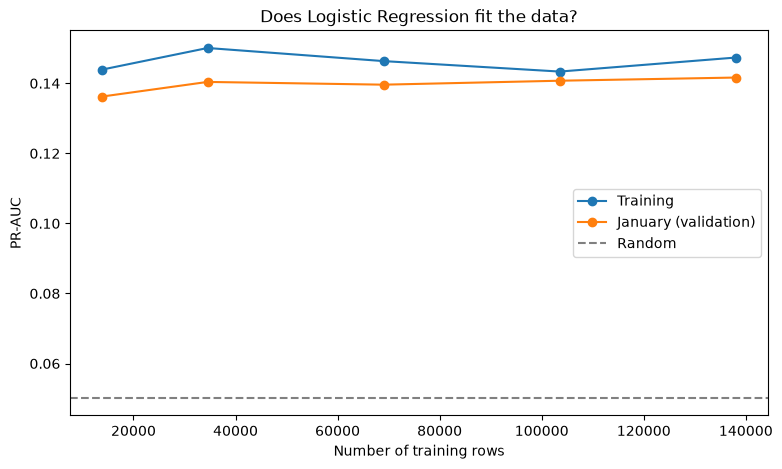

Training: [0.144, 0.15, 0.146, 0.143, 0.147]
January:  [0.136, 0.14, 0.14, 0.141, 0.142]


In [57]:
sizes = [0.1, 0.25, 0.5, 0.75, 1.0]
train_scores, valid_scores = [], []

for s in sizes:
    # train on a part of the training data to see how the model changes with more data
    part = train.sample(frac=s, random_state=42)
    model = make_lr().fit(cap(part)[feature_cols], part["target"])
    train_scores.append(average_precision_score(part["target"], model.predict_proba(cap(part)[feature_cols])[:, 1]))
    valid_scores.append(average_precision_score(y_valid, model.predict_proba(X_valid)[:, 1]))

rows = [int(len(train) * s) for s in sizes]

plt.figure(figsize=(9, 5))
plt.plot(rows, train_scores, marker="o", label="Training")
plt.plot(rows, valid_scores, marker="o", label="January (validation)")
plt.axhline(y_valid.mean(), color="gray", linestyle="--", label="Random")
plt.xlabel("Number of training rows")
plt.ylabel("PR-AUC")
plt.title("Does Logistic Regression fit the data?")
plt.legend()
plt.savefig(fig_path + "logreg_learning_curve.png", bbox_inches="tight")
plt.show()

print("Training:", [round(x, 3) for x in train_scores])
print("January: ", [round(x, 3) for x in valid_scores])

### Is the model stable over time? (Time-based cross-validation)

A normal random K-fold would mix months and let the model learn from the future. Instead, each fold trains on the past and tests on the next month. Outlier limits are learned from each fold's training data only.

- If test scores are close across folds, the model works on different periods, not just January.
- If the training score in each fold is much higher than the test score, the model overfits.

Each month has a different buy rate, so I compare each score with that month's random guess, not just the raw number.

Oct -> Dec       train: 0.148 | test: 0.137 | random: 0.047
Oct+Dec -> Jan   train: 0.147 | test: 0.142 | random: 0.050
Mean test PR-AUC: 0.139


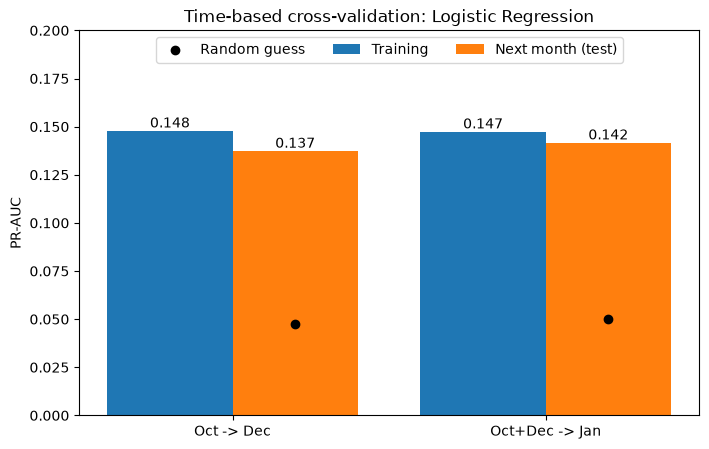

In [59]:
# cap extreme values with limits learned from a given training set
def cap_with(df, limits):
    df = df.copy()
    df[skewed] = df[skewed].clip(upper=limits, axis=1)
    return df

oct_ = train[train["cutoff"] == "2019-10-15"]
dec = train[train["cutoff"] == "2019-12-15"]

# each fold trains on the past and tests on the next month
folds = [("Oct -> Dec", oct_, dec), ("Oct+Dec -> Jan", train, valid)]
fold_train, fold_test, fold_random = [], [], []

for name, tr, te in folds:
    # outlier limits come from this fold's training data only
    limits = tr[skewed].quantile(0.99)
    model = make_lr().fit(cap_with(tr, limits)[feature_cols], tr["target"])
    fold_train.append(average_precision_score(tr["target"], model.predict_proba(cap_with(tr, limits)[feature_cols])[:, 1]))
    fold_test.append(average_precision_score(te["target"], model.predict_proba(cap_with(te, limits)[feature_cols])[:, 1]))
    fold_random.append(te["target"].mean())
    print(f"{name:<16} train: {fold_train[-1]:.3f} | test: {fold_test[-1]:.3f} | random: {fold_random[-1]:.3f}")

print("Mean test PR-AUC:", round(np.mean(fold_test), 3))

# training vs test score in each fold, with the random guess for each month
x = np.arange(len(folds))
plt.figure(figsize=(8, 5))
plt.bar(x - 0.2, fold_train, width=0.4, label="Training")
plt.bar(x + 0.2, fold_test, width=0.4, label="Next month (test)")
plt.scatter(x + 0.2, fold_random, color="black", zorder=3, label="Random guess")

# write the value on top of each bar
for i in x:
    plt.text(i - 0.2, fold_train[i], f"{fold_train[i]:.3f}", ha="center", va="bottom")
    plt.text(i + 0.2, fold_test[i], f"{fold_test[i]:.3f}", ha="center", va="bottom")

plt.xticks(x, [f[0] for f in folds])
plt.ylim(0, 0.2)
plt.ylabel("PR-AUC")
plt.title("Time-based cross-validation: Logistic Regression")
plt.legend(loc="upper center", ncol=3)
plt.savefig(fig_path + "logreg_time_cv.png", bbox_inches="tight")
plt.show()

**Answer:** Logistic Regression is stable but limited.

- **Stable over time:** the test score is almost the same in both folds (0.137 and 0.142), and each one is about 2.9 times the random guess for that month. So the result on January was not luck.
- **No overfitting:** the training and test scores are very close (a gap of about 0.01).
- **Underfitting:** even on its own training data, the model doesn't go above 0.15. The problem is not that it fails to generalize, it's that it can't learn more. A model that only draws straight lines has reached its limit with these features.

This is my reason for trying LightGBM: not just because it's "stronger," but because the results show the simple model has hit a ceiling. Training on October alone also generalized well to December (0.137), which confirms October doesn't hurt.

## Step 8: LightGBM

**Why I add it:** time-based cross-validation showed that Logistic Regression is stable but underfits: even on its own training data it doesn't go above 0.15. A model that only draws straight lines has reached its limit.

**What it does:** LightGBM builds many small decision trees, one after another. Each new tree focuses on the mistakes of the trees before it, and the final prediction combines all of them. This lets it learn curves (like the two peaks in the buy rate by hour, Q2) and combinations (like a recent cart mattering more for active users).

**What it doesn't need:** trees split on thresholds like "views > 5", so extreme values, different scales, and missing values don't affect them. I give it the features as they are.

**The risk:** with too many trees, it memorizes the training data. I stop adding trees when January stops improving, and I run the same fit and stability checks as Logistic Regression.

**The bar to beat:** Logistic Regression, PR-AUC 0.142 on January.

In [60]:
import lightgbm as lgb

# lightgbm uses the features as they are, with missing values and no capping
X_train_raw, X_valid_raw = train[feature_cols], valid[feature_cols]

# track both training and January scores after every tree
lgbm = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=31, metric="average_precision", verbose=-1)
lgbm.fit(X_train_raw, train["target"],
         eval_set=[(X_train_raw, train["target"]), (X_valid_raw, y_valid)],
         callbacks=[lgb.early_stopping(50, verbose=False)])

show("LightGBM on training", train["target"], lgbm.predict_proba(X_train_raw)[:, 1])
show("LightGBM on January", y_valid, lgbm.predict_proba(X_valid_raw)[:, 1])
print("Best number of trees:", lgbm.best_iteration_)

c:\Users\esraa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM on training         PR-AUC: 0.232 | ROC-AUC: 0.865
LightGBM on January          PR-AUC: 0.156 | ROC-AUC: 0.751
Best number of trees: 50


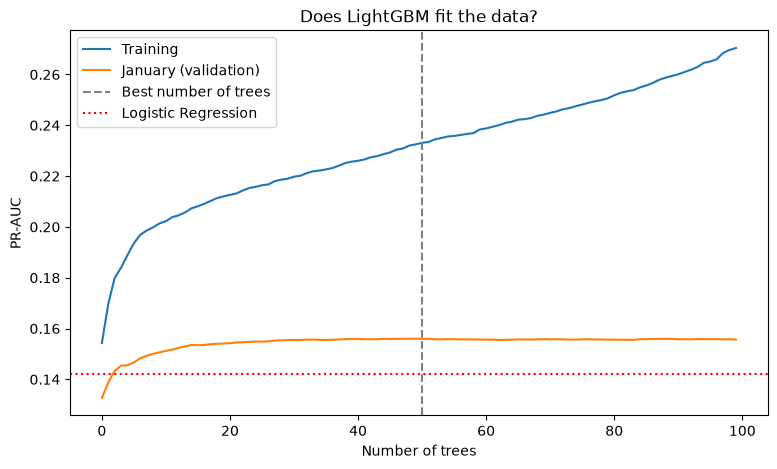

In [61]:
# scores after each tree: first for training, then for January
results = list(lgbm.evals_result_.values())
train_curve = results[0]["average_precision"]
valid_curve = results[1]["average_precision"]

plt.figure(figsize=(9, 5))
plt.plot(train_curve, label="Training")
plt.plot(valid_curve, label="January (validation)")
plt.axvline(lgbm.best_iteration_, color="gray", linestyle="--", label="Best number of trees")
plt.axhline(0.142, color="red", linestyle=":", label="Logistic Regression")
plt.xlabel("Number of trees")
plt.ylabel("PR-AUC")
plt.title("Does LightGBM fit the data?")
plt.legend()
plt.savefig(fig_path + "lightgbm_fit.png", bbox_inches="tight")
plt.show()

                Rule (recent cart)  Logistic Regression  LightGBM  Random
Oct -> Dec                   0.100                0.137     0.143   0.047
Oct+Dec -> Jan               0.104                0.142     0.156   0.050


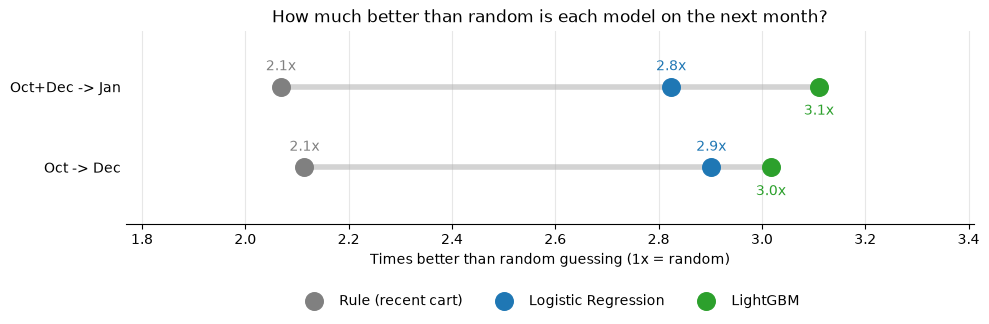

In [64]:
# same folds as Logistic Regression, with the number of trees found above
best_trees = lgbm.best_iteration_
lgb_test, rule_test = [], []

for name, tr, te in folds:
    m = lgb.LGBMClassifier(n_estimators=best_trees, learning_rate=0.05, num_leaves=31, verbose=-1)
    m.fit(tr[feature_cols], tr["target"])
    lgb_test.append(average_precision_score(te["target"], m.predict_proba(te[feature_cols])[:, 1]))
    rule_test.append(average_precision_score(te["target"], -te["days_since_last_cart"]))

models = {"Rule (recent cart)": rule_test, "Logistic Regression": fold_test, "LightGBM": lgb_test}
colors = {"Rule (recent cart)": "gray", "Logistic Regression": "tab:blue", "LightGBM": "tab:green"}
offsets = {"Rule (recent cart)": 12, "Logistic Regression": 12, "LightGBM": -20}
fold_names = [f[0] for f in folds]
y_pos = np.arange(len(fold_names))

# raw scores in a table
summary = pd.DataFrame(models, index=fold_names)
summary["Random"] = fold_random
print(summary.round(3))

fig, ax = plt.subplots(figsize=(10, 3.6))

# a gray line from the weakest to the strongest model in each fold
all_lifts = []
for i in y_pos:
    lifts = [models[m][i] / fold_random[i] for m in models]
    all_lifts += lifts
    ax.plot([min(lifts), max(lifts)], [i, i], color="lightgray", linewidth=4, zorder=1)

# one dot per model, with its value in the same color
for name, scores in models.items():
    lift = np.array(scores) / np.array(fold_random)
    ax.scatter(lift, y_pos, s=160, color=colors[name], label=name, zorder=3)
    for l, y in zip(lift, y_pos):
        ax.annotate(f"{l:.1f}x", (l, y), textcoords="offset points", xytext=(0, offsets[name]), ha="center", fontsize=10, color=colors[name])

# keep the axis close to the real values and the rows close together
ax.set_xlim(min(all_lifts) - 0.3, max(all_lifts) + 0.3)
ax.set_ylim(-0.7, len(fold_names) - 0.3)
ax.set_yticks(y_pos, fold_names)
ax.set_xlabel("Times better than random guessing (1x = random)")
ax.set_title("How much better than random is each model on the next month?")

# clean look: legend below, no box lines except the bottom
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.savefig(fig_path + "model_comparison_cv.png", bbox_inches="tight")
plt.show()

**Answer:** LightGBM is better than Logistic Regression in both folds, so the improvement is consistent, not luck from one month.

| Fold | Rule | Logistic Regression | LightGBM |
|---|---|---|---|
| Oct → Dec | 0.100 (2.1x) | 0.137 (2.9x) | 0.143 (3.0x) |
| Oct+Dec → Jan | 0.104 (2.1x) | 0.142 (2.8x) | 0.156 (3.1x) |

The improvement is modest: about 4% in the first fold and about 10% in the second. The second fold is a bit optimistic, because the number of trees was chosen on January, so the real gain is probably somewhere in between.

One thing stands out: LightGBM gets better when it has more training data (October alone vs October + December), while Logistic Regression stays about the same. This matches what I found before: the simple model has reached its limit, while LightGBM can still learn more from the data.

The simple rule stays at 2.1x in both folds, which confirms it is a strong and stable baseline.

### Does LightGBM overfit?

I compare the score on training data with the score on January, after every tree. If the training line keeps going up while January stops or goes down, the model is starting to memorize the training data. Early stopping picks the number of trees where January was best.

In [66]:
import lightgbm as lgb

# lightgbm uses the features as they are, with missing values and no capping
X_train_raw, X_valid_raw = train[feature_cols], valid[feature_cols]

# track both training and January scores after every tree
lgbm = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=31, metric="average_precision", verbose=-1)
lgbm.fit(X_train_raw, train["target"],
         eval_set=[(X_train_raw, train["target"]), (X_valid_raw, y_valid)],
         callbacks=[lgb.early_stopping(50, verbose=False)])

show("LightGBM on training", train["target"], lgbm.predict_proba(X_train_raw)[:, 1])
show("LightGBM on January", y_valid, lgbm.predict_proba(X_valid_raw)[:, 1])
print("Best number of trees:", lgbm.best_iteration_)

c:\Users\esraa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM on training         PR-AUC: 0.232 | ROC-AUC: 0.865
LightGBM on January          PR-AUC: 0.156 | ROC-AUC: 0.751
Best number of trees: 50


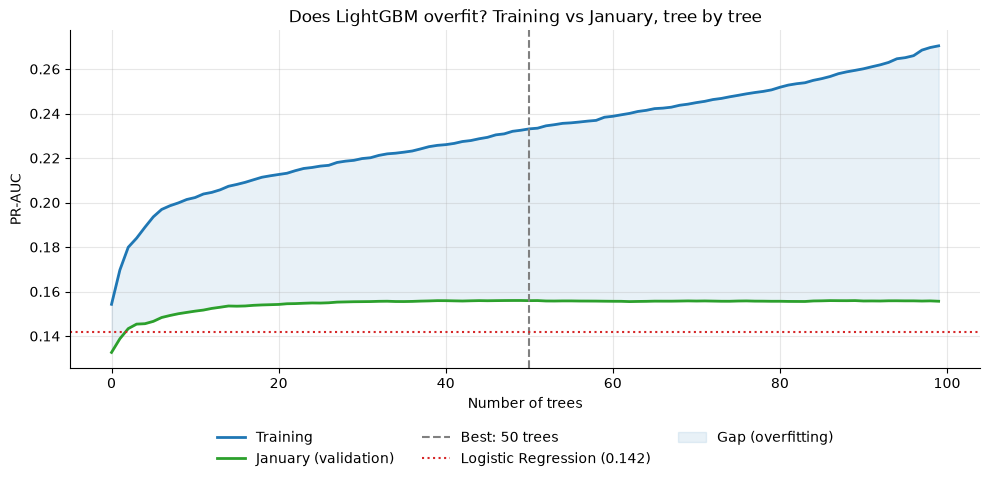

In [67]:
# scores after each tree: first for training, then for January
results = list(lgbm.evals_result_.values())
train_curve = results[0]["average_precision"]
valid_curve = results[1]["average_precision"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_curve, color="tab:blue", linewidth=2, label="Training")
ax.plot(valid_curve, color="tab:green", linewidth=2, label="January (validation)")
ax.axvline(lgbm.best_iteration_, color="gray", linestyle="--", label=f"Best: {lgbm.best_iteration_} trees")
ax.axhline(0.142, color="tab:red", linestyle=":", label="Logistic Regression (0.142)")

# shade the gap between training and January
ax.fill_between(range(len(train_curve)), valid_curve, train_curve, color="tab:blue", alpha=0.1, label="Gap (overfitting)")

ax.set_xlabel("Number of trees")
ax.set_ylabel("PR-AUC")
ax.set_title("Does LightGBM overfit? Training vs January, tree by tree")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(fig_path + "lightgbm_fit.png", bbox_inches="tight")
plt.show()

**Answer:** Yes, LightGBM overfits, but it doesn't hurt the January score.

January improves quickly in the first 20 trees or so, then stays flat at about 0.156. The training score keeps going up the whole time, from about 0.155 to about 0.27. At the 50 trees early stopping chose, the gap is about 0.08, and it keeps growing. After the first trees, the model is memorizing training data instead of learning patterns that work on other months.

The good news: January never goes down, and it stays above Logistic Regression (0.156 vs 0.142) the whole time. But a gap of 0.08, compared with 0.005 for Logistic Regression, means I should make the trees simpler and see if I can keep the January score with less memorization.

In [68]:
rows = []

# try simpler trees and see which keeps January high with a smaller gap
for leaves in [7, 15, 31]:
    for min_child in [20, 200, 500]:
        m = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=leaves, min_child_samples=min_child,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8, metric="average_precision", verbose=-1)
        m.fit(X_train_raw, train["target"], eval_set=[(X_valid_raw, y_valid)], callbacks=[lgb.early_stopping(50, verbose=False)])
        tr_score = average_precision_score(train["target"], m.predict_proba(X_train_raw)[:, 1])
        va_score = average_precision_score(y_valid, m.predict_proba(X_valid_raw)[:, 1])
        rows.append({"leaves": leaves, "min_child": min_child, "trees": m.best_iteration_,
                     "train": tr_score, "january": va_score, "gap": tr_score - va_score})

tuning = pd.DataFrame(rows).sort_values("january", ascending=False)
print(tuning.round(3))

c:\Users\esraa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\esraa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\esraa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\esraa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is depreca

   leaves  min_child  trees  train  january    gap
8      31        500     66  0.197    0.160  0.037
4      15        200     62  0.181    0.159  0.022
6      31         20     63  0.238    0.159  0.079
5      15        500     75  0.179    0.159  0.021
7      31        200    102  0.229    0.158  0.071
3      15         20     81  0.192    0.158  0.034
2       7        500    194  0.180    0.155  0.024
1       7        200    176  0.181    0.155  0.026
0       7         20    176  0.188    0.154  0.034


c:\Users\esraa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Final LightGBM on training   PR-AUC: 0.179 | ROC-AUC: 0.852
Final LightGBM on January    PR-AUC: 0.159 | ROC-AUC: 0.750
Best number of trees: 75


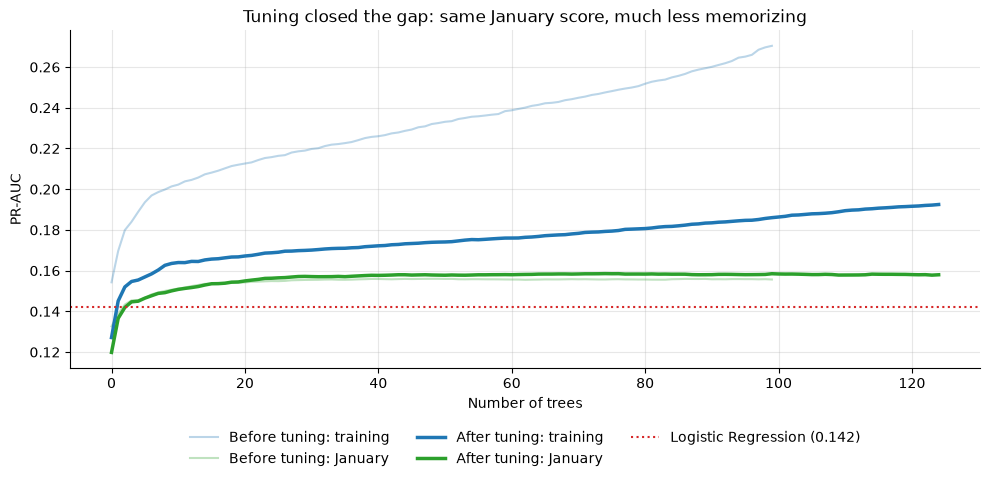

In [69]:
# final settings chosen on January
params = dict(learning_rate=0.05, num_leaves=15, min_child_samples=500,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)

lgbm_final = lgb.LGBMClassifier(n_estimators=1000, metric="average_precision", **params)
lgbm_final.fit(X_train_raw, train["target"],
               eval_set=[(X_train_raw, train["target"]), (X_valid_raw, y_valid)],
               callbacks=[lgb.early_stopping(50, verbose=False)])

show("Final LightGBM on training", train["target"], lgbm_final.predict_proba(X_train_raw)[:, 1])
show("Final LightGBM on January", y_valid, lgbm_final.predict_proba(X_valid_raw)[:, 1])
print("Best number of trees:", lgbm_final.best_iteration_)

# scores after each tree for the tuned model
results = list(lgbm_final.evals_result_.values())
new_train = results[0]["average_precision"]
new_valid = results[1]["average_precision"]

fig, ax = plt.subplots(figsize=(10, 5))

# faded lines: the first model, bold lines: the tuned model
ax.plot(train_curve, color="tab:blue", alpha=0.3, label="Before tuning: training")
ax.plot(valid_curve, color="tab:green", alpha=0.3, label="Before tuning: January")
ax.plot(new_train, color="tab:blue", linewidth=2.5, label="After tuning: training")
ax.plot(new_valid, color="tab:green", linewidth=2.5, label="After tuning: January")
ax.axhline(0.142, color="tab:red", linestyle=":", label="Logistic Regression (0.142)")

ax.set_xlabel("Number of trees")
ax.set_ylabel("PR-AUC")
ax.set_title("Tuning closed the gap: same January score, much less memorizing")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(fig_path + "lightgbm_tuning.png", bbox_inches="tight")
plt.show()

### Tuning: can simpler trees keep the January score with less overfitting?

**What is it?** A model has two kinds of settings: things it learns on its own from the data (the rules inside the trees), and things I choose before training (like tree size, or the minimum number of users in each leaf). The second kind are called hyperparameters. Tuning means trying different values for them and keeping the best one, judged on January only.

**What we do:** try smaller trees (num_leaves), a minimum number of users per leaf (min_child_samples), and let each tree see only 80% of rows and features.
**Why:** the default settings made the model memorize the training data (a gap of 0.08).
**How I choose, decided before seeing the results:** the highest January score. If two settings are within 0.002, I pick the one with the smaller gap, because it is simpler and more likely to hold on February.

### Comparing with Random Forest

**What is it?** Random Forest builds many deep decision trees, each one on a random sample of rows and features, and averages their predictions. Unlike LightGBM, the trees are built independently, not one after another to fix earlier mistakes.

**What we do:** train Random Forest with three settings for the minimum number of users per leaf (min_samples_leaf), and compare it with LightGBM on January, including the training gap.
**Why:** comparing two different ways of building trees shows whether LightGBM is really the better choice, not just the one I tried.

*Random Forest in scikit-learn needs missing values filled, so I fill them with the training median inside a pipeline. All settings are judged on January, with the same rule as before.*

In [70]:
from sklearn.ensemble import RandomForestClassifier

rows = []

# try three leaf sizes, from more detailed trees to simpler ones
for leaf in [20, 100, 500]:
    rf = make_pipeline(SimpleImputer(strategy="median"),
                       RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, max_features="sqrt", n_jobs=-1, random_state=42))
    rf.fit(X_train_raw, train["target"])
    tr_score = average_precision_score(train["target"], rf.predict_proba(X_train_raw)[:, 1])
    va_score = average_precision_score(y_valid, rf.predict_proba(X_valid_raw)[:, 1])
    rows.append({"min_samples_leaf": leaf, "train": tr_score, "january": va_score, "gap": tr_score - va_score})

rf_results = pd.DataFrame(rows)
print(rf_results.round(3))

   min_samples_leaf  train  january    gap
0                20  0.437    0.155  0.282
1               100  0.211    0.156  0.055
2               500  0.161    0.150  0.012


**Answer:** LightGBM is the better choice.

| Model | PR-AUC (January) | Times better than random | Gap (train − January) |
|---|---|---|---|
| Random guess | 0.050 | 1.0x | — |
| Rule (recent cart) | 0.104 | 2.1x | — |
| Logistic Regression | 0.142 | 2.8x | 0.005 |
| Random Forest (min_samples_leaf = 100) | 0.156 | 3.1x | 0.055 |
| **LightGBM (tuned)** | **0.159** | **3.2x** | **0.021** |

The best Random Forest reached 0.156 on January, 0.003 below LightGBM, so by my rule LightGBM wins. More importantly, it wins on both sides: a higher score and less than half the memorization.

**What Random Forest taught me:** with small leaves (20 users), it scored 0.437 on training data but only 0.155 on January. Its training score almost tripled, and January didn't improve at all. This is the clearest proof in the project that a high training score means nothing on its own. It's the same lesson as with LightGBM: the minimum number of users per leaf is the most important setting against overfitting.

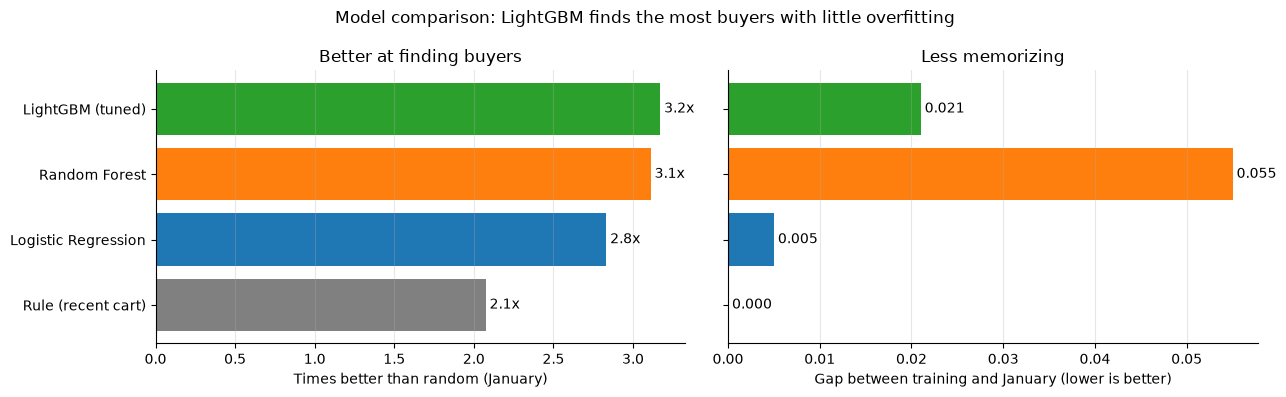

In [71]:
names = ["Rule (recent cart)", "Logistic Regression", "Random Forest", "LightGBM (tuned)"]
scores = [0.104, 0.142, 0.156, 0.159]
gaps = [0, 0.005, 0.055, 0.021]
colors = ["gray", "tab:blue", "tab:orange", "tab:green"]
lift = [s / y_valid.mean() for s in scores]

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

# left: how much better than random
axes[0].barh(names, lift, color=colors)
for i, v in enumerate(lift):
    axes[0].text(v, i, f" {v:.1f}x", va="center")
axes[0].set_xlabel("Times better than random (January)")
axes[0].set_title("Better at finding buyers")

# right: how much each model memorizes
axes[1].barh(names, gaps, color=colors)
for i, v in enumerate(gaps):
    axes[1].text(v, i, f" {v:.3f}", va="center")
axes[1].set_xlabel("Gap between training and January (lower is better)")
axes[1].set_title("Less memorizing")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)

plt.suptitle("Model comparison: LightGBM finds the most buyers with little overfitting")
plt.tight_layout()
plt.savefig(fig_path + "final_model_comparison.png", bbox_inches="tight")
plt.show()

### LightGBM vs Random Forest on the real users of January

**Precision-Recall curve — what is it?** I rank users from most to least likely to buy and pick them one by one. At each point, the curve shows what share of buyers I've found (x-axis) and what share of the users I picked actually bought (y-axis). Higher is better.

**Gains curve — what is it?** If the store contacts only the top X% of users ranked by the model, what share of all buyers does it reach? The dashed line is random: contacting 10% of users at random reaches 10% of buyers. The faster a curve rises above it, the more money the model saves.

**Why:** a single score can hide differences. These charts show how each model behaves on real users, especially at the top of the ranking, where a real campaign would focus.

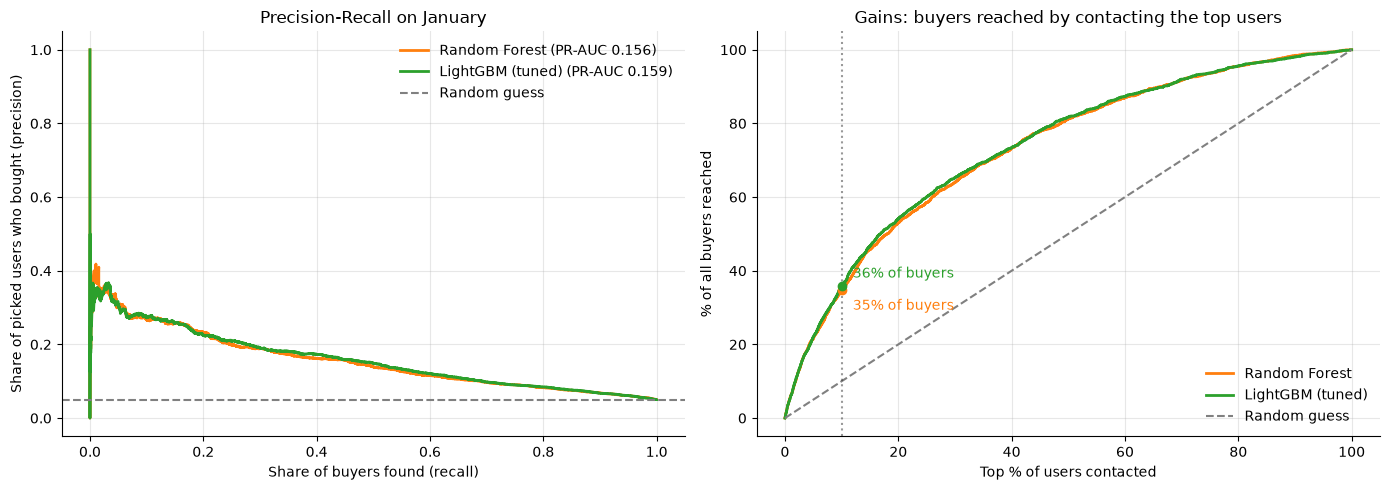

In [72]:
from sklearn.metrics import precision_recall_curve

# refit the best random forest (min_samples_leaf = 100)
rf_best = make_pipeline(SimpleImputer(strategy="median"),
                        RandomForestClassifier(n_estimators=300, min_samples_leaf=100, max_features="sqrt", n_jobs=-1, random_state=42))
rf_best.fit(X_train_raw, train["target"])

scores = {
    "Random Forest": rf_best.predict_proba(X_valid_raw)[:, 1],
    "LightGBM (tuned)": lgbm_final.predict_proba(X_valid_raw)[:, 1]
}
colors = {"Random Forest": "tab:orange", "LightGBM (tuned)": "tab:green"}
offsets = {"Random Forest": -14, "LightGBM (tuned)": 6}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left: precision at each share of buyers found
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y_valid, s)
    axes[0].plot(r, p, color=colors[name], linewidth=2, label=f"{name} (PR-AUC {average_precision_score(y_valid, s):.3f})")
axes[0].axhline(y_valid.mean(), color="gray", linestyle="--", label="Random guess")
axes[0].set_xlabel("Share of buyers found (recall)")
axes[0].set_ylabel("Share of picked users who bought (precision)")
axes[0].set_title("Precision-Recall on January")
axes[0].legend(frameon=False)

# right: share of buyers reached when contacting the top users
for name, s in scores.items():
    order = y_valid.values[np.argsort(-s)]
    captured = np.cumsum(order) / order.sum() * 100
    pct = np.arange(1, len(order) + 1) / len(order) * 100
    axes[1].plot(pct, captured, color=colors[name], linewidth=2, label=name)

    # mark what happens if the store contacts the top 10%
    at10 = captured[int(len(order) * 0.10) - 1]
    axes[1].scatter(10, at10, color=colors[name], zorder=3)
    axes[1].annotate(f"{at10:.0f}% of buyers", (10, at10), textcoords="offset points", xytext=(8, offsets[name]), color=colors[name])

axes[1].plot([0, 100], [0, 100], color="gray", linestyle="--", label="Random guess")
axes[1].axvline(10, color="black", linestyle=":", alpha=0.4)
axes[1].set_xlabel("Top % of users contacted")
axes[1].set_ylabel("% of all buyers reached")
axes[1].set_title("Gains: buyers reached by contacting the top users")
axes[1].legend(frameon=False, loc="lower right")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(fig_path + "lgbm_vs_rf_curves.png", bbox_inches="tight")
plt.show()

### Why are the two models so close, and which one do I choose?

**Why they are close:**
1. **Same family.** Random Forest and LightGBM are both built from decision trees, and trees learn the same kind of rules: "if the last cart was less than two days ago and views are above 5...". They differ in how they combine trees, not in the rules they can learn, so they find the same patterns.
2. **The signal is in a few strong features.** The EDA and the baselines showed that cart activity and how recent it is carry most of the information. Both models found it quickly, and after that there is very little left to compete for.
3. **Part of the decision is not in the data.** People buy or don't buy for reasons the store can't see: payday, a cheaper price elsewhere, being busy, getting a gift. This puts a ceiling on any model, however strong.

The results show this ceiling: Logistic Regression (straight lines only) reached 0.142, and the tree models reached 0.156–0.159. Moving to trees added about 10%, and then it stopped.

**Which one I choose: LightGBM.** The scores are almost equal, so the choice comes down to the other differences:
- **It memorizes less than half as much** (gap 0.021 vs 0.055), so it is more likely to hold on February and on new data.
- **It is faster and lighter**, which matters when it runs in a real app.
- **It handles missing values on its own**, so the deployed model needs less preprocessing.
- **It has SHAP built in**, so I can explain each prediction without extra tools.

## Step 9: Explaining the Model with SHAP

**What is it?** SHAP comes from a fair way to split a team's prize between players based on how much each one contributed. Here, the players are the features and the prize is the model's prediction for one user. SHAP shows how much each feature pushed that user toward buying (positive) or away from it (negative). Starting from the average prediction and adding all the pushes gives exactly the model's prediction.

**What we do:** calculate SHAP values on January, rank features by their average effect, see how the top features change the prediction, and explain one user in detail.
**Why:** to see what the model really relies on, check that it matches the EDA, catch any sign of leakage (one feature dominating in a strange way), and show a business why a user was picked.

*I use the SHAP values built into LightGBM, so no extra library is needed. Values are on the log-odds scale: positive raises the chance of buying, negative lowers it.*

In [79]:
%pip install shap

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   -------------------------- ----------- 524.3/751.9 kB 584.2 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 584.2 kB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 547.7 kB/s  0:00:01
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

   ---------------------------------------- 0/3 [slicer]
   -------------------------- ------------- 2/3 [shap]
   --------------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [80]:
import shap

# shap's tree explainer reads the lightgbm trees directly
explainer = shap.TreeExplainer(lgbm_final)
sample = X_valid_raw.sample(5000, random_state=42)
sv = explainer(sample)

# some shap versions return both classes; keep only "buys"
if len(sv.shape) == 3:
    sv = sv[:, :, 1]

c:\Users\esraa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [84]:
# one clean style for every chart in the project
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9CA3AF", "axes.labelcolor": "#374151",
    "xtick.color": "#4B5563", "ytick.color": "#4B5563",
    "axes.grid": True, "grid.alpha": 0.25
})

TEAL, CORAL, GRAY, DARK = "#0F766E", "#E76F51", "#CBD5E1", "#374151"
X_plot = X_valid_raw.reset_index(drop=True)

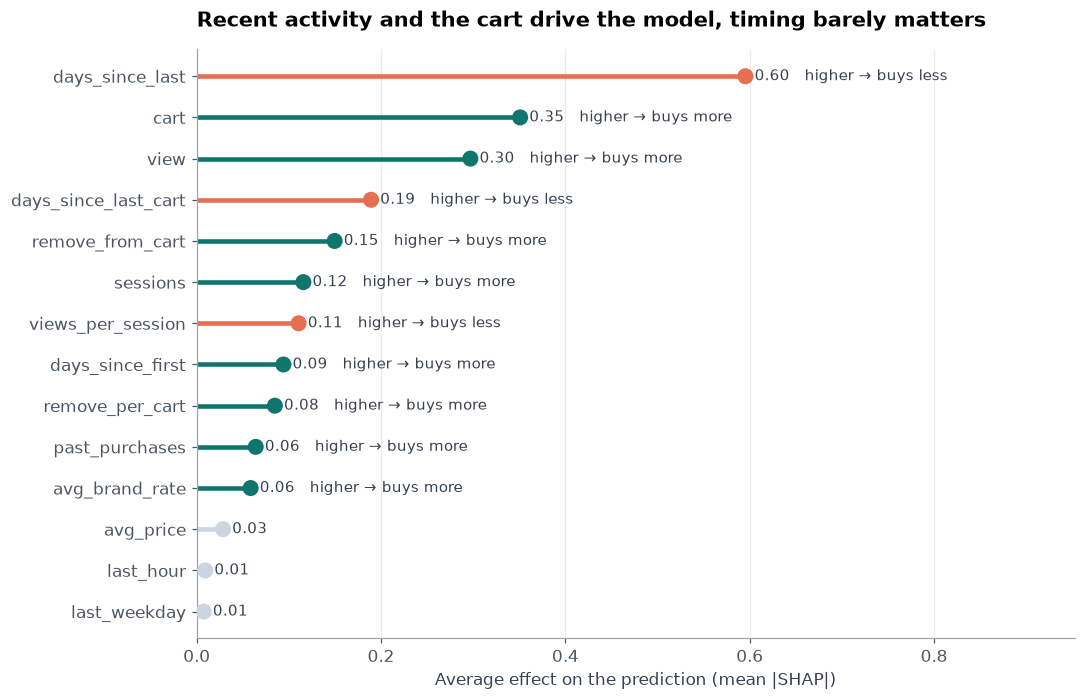

In [85]:
imp = shap_values.abs().mean().sort_values()

# direction: does a higher value push toward buying or away?
direction = {c: X_plot[c].corr(shap_values[c], method="spearman") for c in imp.index}
colors = [GRAY if imp[c] < 0.05 else (TEAL if direction[c] > 0 else CORAL) for c in imp.index]

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.hlines(imp.index, 0, imp.values, color=colors, linewidth=3)
ax.scatter(imp.values, imp.index, color=colors, s=90, zorder=3)

# label each feature with its size and direction
for c in imp.index:
    note = "" if imp[c] < 0.05 else ("higher → buys more" if direction[c] > 0 else "higher → buys less")
    ax.text(imp[c] + 0.01, c, f"{imp[c]:.2f}   {note}", va="center", color=DARK, fontsize=10)

ax.set_xlim(0, imp.max() * 1.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Average effect on the prediction (mean |SHAP|)")
ax.set_title("Recent activity and the cart drive the model, timing barely matters", pad=15)

plt.tight_layout()
plt.savefig(fig_path + "shap_drivers.png", bbox_inches="tight")
plt.show()

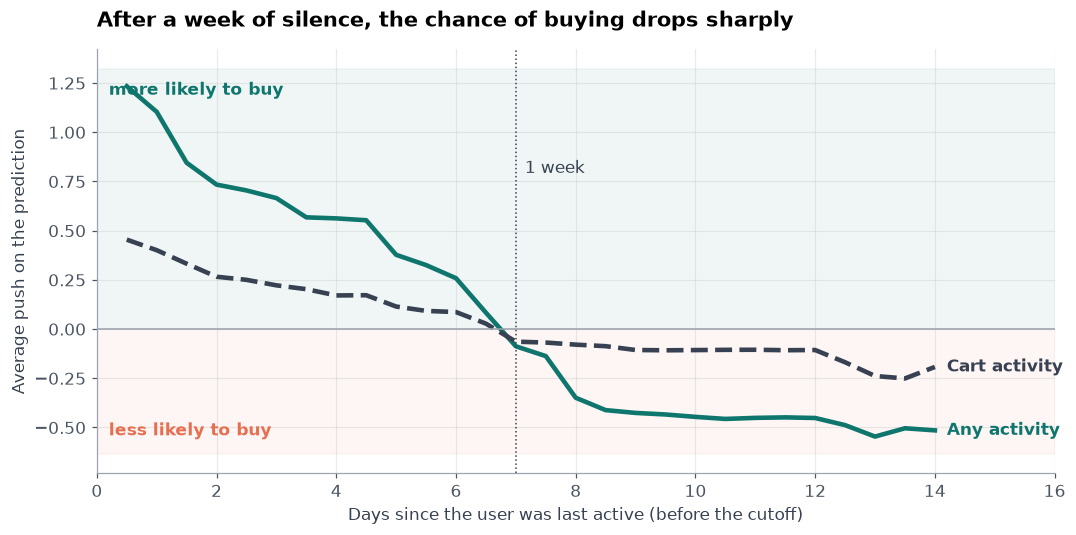

In [86]:
days = np.arange(0, 14.5, 0.5)
fig, ax = plt.subplots(figsize=(10, 5))

# average push for each half day of silence
for col, color, name, style in [("days_since_last", TEAL, "Any activity", "-"), ("days_since_last_cart", DARK, "Cart activity", "--")]:
    line = shap_values[col].groupby(pd.cut(X_plot[col], days), observed=True).mean()
    x = [b.right for b in line.index]
    ax.plot(x, line.values, color=color, linewidth=3, linestyle=style)
    ax.text(x[-1] + 0.2, line.values[-1], name, color=color, va="center", fontweight="bold")

# soft zones: above zero helps, below zero hurts
low, high = ax.get_ylim()
ax.axhspan(0, high, color=TEAL, alpha=0.06)
ax.axhspan(low, 0, color=CORAL, alpha=0.06)
ax.text(0.2, high * 0.9, "more likely to buy", color=TEAL, fontweight="bold")
ax.text(0.2, low * 0.85, "less likely to buy", color=CORAL, fontweight="bold")
ax.axvline(7, color=DARK, linestyle=":", linewidth=1)
ax.text(7.15, high * 0.6, "1 week", color=DARK)

ax.axhline(0, color="#9CA3AF", linewidth=1)
ax.set_xlim(0, 16)
ax.set_xlabel("Days since the user was last active (before the cutoff)")
ax.set_ylabel("Average push on the prediction")
ax.set_title("After a week of silence, the chance of buying drops sharply", pad=15)

plt.tight_layout()
plt.savefig(fig_path + "shap_week_rule.png", bbox_inches="tight")
plt.show()

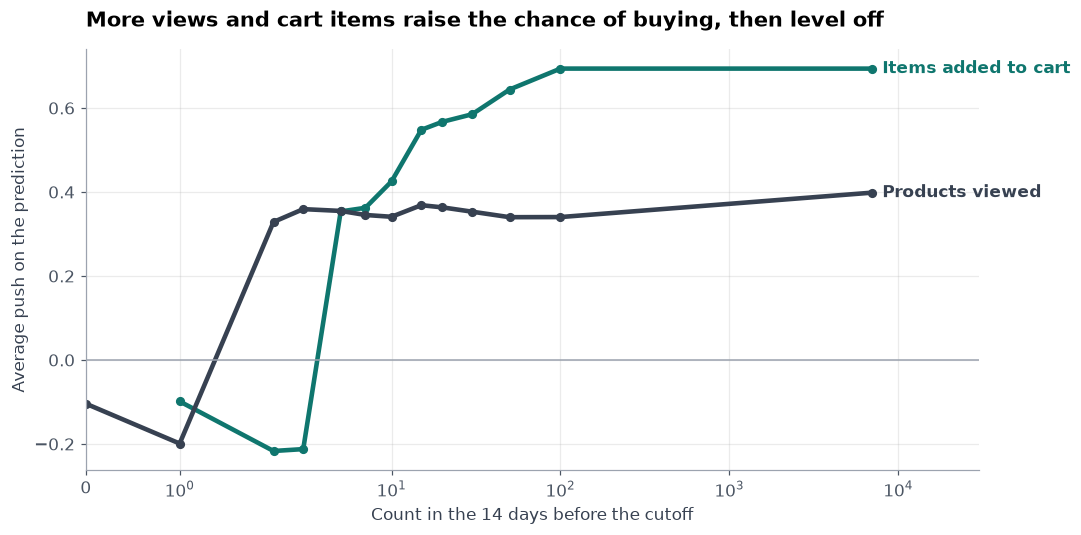

In [87]:
counts = [-1, 0, 1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 100, 7000]
fig, ax = plt.subplots(figsize=(10, 5))

for col, color, name in [("cart", TEAL, "Items added to cart"), ("view", DARK, "Products viewed")]:
    line = shap_values[col].groupby(pd.cut(X_plot[col], counts), observed=True).mean()
    x = [b.right for b in line.index]
    ax.plot(x, line.values, color=color, linewidth=3, marker="o", markersize=5)
    ax.text(x[-1] * 1.15, line.values[-1], name, color=color, va="center", fontweight="bold")

ax.axhline(0, color="#9CA3AF", linewidth=1)
ax.set_xscale("symlog")
ax.set_xlim(0, 30000)
ax.set_xlabel("Count in the 14 days before the cutoff")
ax.set_ylabel("Average push on the prediction")
ax.set_title("More views and cart items raise the chance of buying, then level off", pad=15)

plt.tight_layout()
plt.savefig(fig_path + "shap_activity.png", bbox_inches="tight")
plt.show()

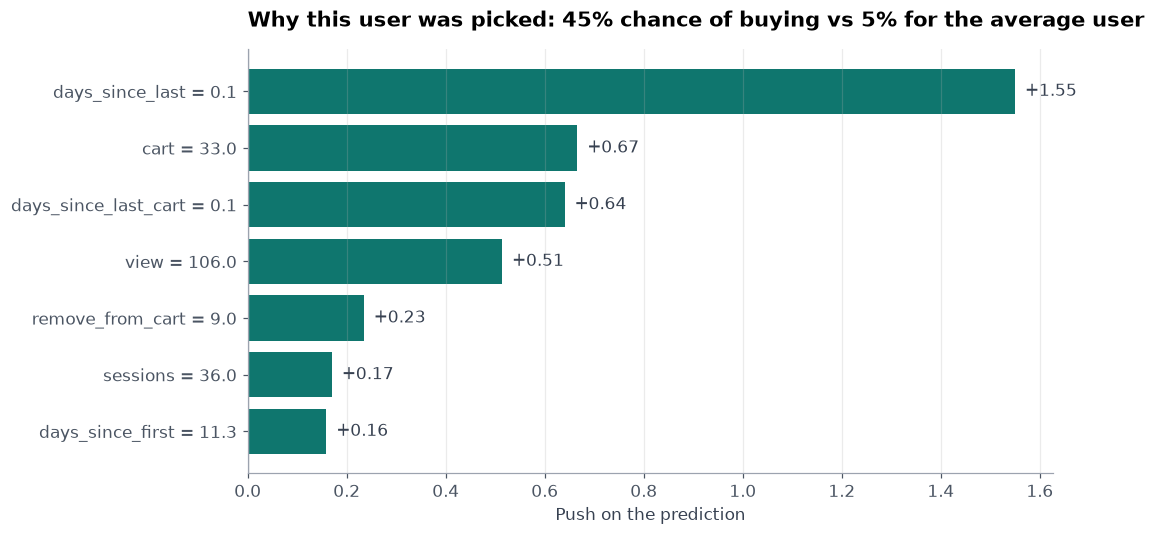

In [88]:
probs = lgbm_final.predict_proba(X_valid_raw)[:, 1]
i = np.argmax(probs)
one = shap_values.iloc[i]
top = one.abs().sort_values().index[-7:]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh([f"{c} = {X_plot.loc[i, c]:.1f}" for c in top], one[top], color=[TEAL if v > 0 else CORAL for v in one[top]])

# write each push next to its bar
for k, v in enumerate(one[top]):
    ax.text(v, k, f"  {v:+.2f}", va="center", color=DARK)

ax.axvline(0, color="#9CA3AF")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Push on the prediction")
ax.set_title(f"Why this user was picked: {probs[i]:.0%} chance of buying vs {probs.mean():.0%} for the average user", pad=15)

plt.tight_layout()
plt.savefig(fig_path + "shap_one_user.png", bbox_inches="tight")
plt.show()

**Answer:** The model relies on behavior, and it matches the EDA.

- **How recently the user was active is the strongest signal**, by far. After about a week of no activity, its push turns negative and the chance of buying drops sharply. This matches Q3: 84% of buyers buy within 7 days.
- **Cart and views come next.** More activity raises the chance of buying, then levels off.
- **Time since the last cart action also matters**, which matches Q8: most buyers check out soon after the cart.
- **Price barely matters**, which confirms Q6.
- **The hour and weekday of the last visit have almost no effect.** In the EDA, the buy rate changed by hour, but once the model knows how active and how recent a user is, the time of their last visit adds nothing.

**No sign of leakage:** no single feature dominates in a strange way, and the top features are exactly the behaviors I expected from the EDA.

This also explains why LightGBM and Random Forest scored the same: the signal sits in a few strong behavior features, and both models found them.

## Step 10: Choosing the Threshold

**What is it?** The model gives each user a chance of buying, like 23%. A business needs a yes or no: send a reminder or not. The threshold is the number above which the answer is yes.

**What we do:** compare two ways to choose it, on January only: the threshold with the best F1 (a balance between precision and recall), and a budget threshold where the store contacts only the top 10% of users.
**Why:** there is no single right threshold. A high one contacts fewer people, and most of them buy, but misses many buyers. A low one reaches more buyers but also contacts many who won't buy. The choice depends on the business goal.
**Why it matters:** the threshold is chosen on January and then used as is on February, so February stays a fair test.

In [89]:
from sklearn.metrics import precision_recall_curve

valid_probs = lgbm_final.predict_proba(X_valid_raw)[:, 1]

# option 1: the threshold with the best F1 on January
p, r, t = precision_recall_curve(y_valid, valid_probs)
f1 = 2 * p * r / (p + r + 1e-9)
best = np.argmax(f1[:-1])
f1_threshold = t[best]
print(f"Best F1:     threshold {f1_threshold:.3f} | precision {p[best]:.2f} | recall {r[best]:.2f} | F1 {f1[best]:.2f}")

# option 2: a budget to contact only the top 10% of users
budget_threshold = np.quantile(valid_probs, 0.90)
picked = valid_probs >= budget_threshold
prec = y_valid[picked].mean()
rec = y_valid[picked].sum() / y_valid.sum()
print(f"Top 10%:     threshold {budget_threshold:.3f} | precision {prec:.2f} | recall {rec:.2f} | F1 {2 * prec * rec / (prec + rec):.2f}")

Best F1:     threshold 0.098 | precision 0.17 | recall 0.41 | F1 0.24
Top 10%:     threshold 0.107 | precision 0.18 | recall 0.36 | F1 0.24


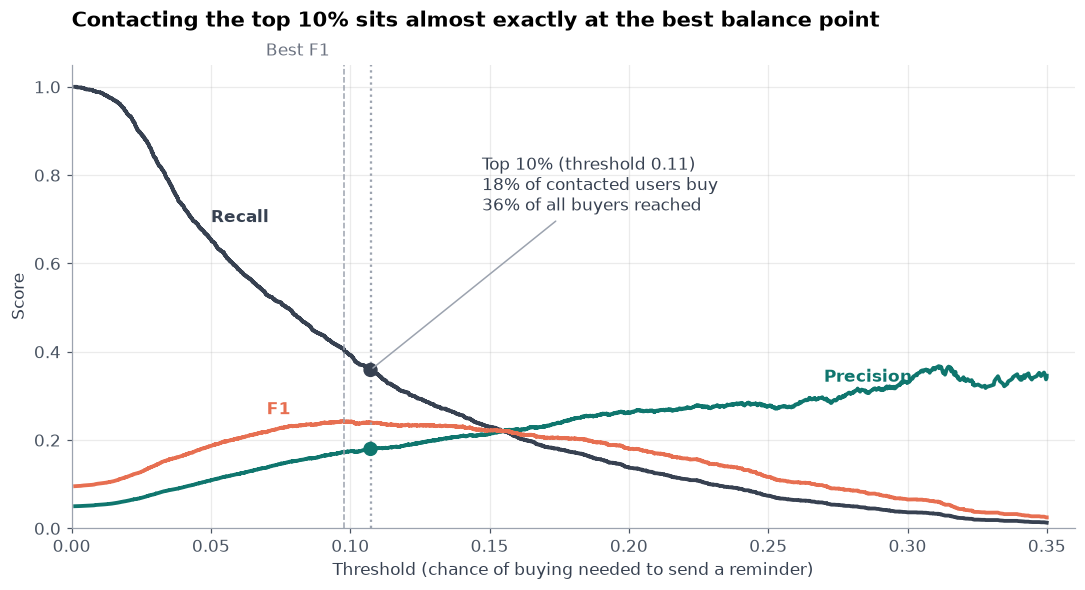

In [93]:
fig, ax = plt.subplots(figsize=(10, 5.5))

# past 0.35 only a handful of users are left, so the lines just jump around
keep = t <= 0.35
for values, color, name, x in [(p[:-1], TEAL, "Precision", 0.27), (r[:-1], DARK, "Recall", 0.05), (f1[:-1], CORAL, "F1", 0.07)]:
    ax.plot(t[keep], values[keep], color=color, linewidth=2.5)
    # write each name where its line is easy to read
    k = np.searchsorted(t, x)
    ax.text(x, values[k] + 0.04, name, color=color, fontweight="bold")

# the chosen threshold, with what it means
k = np.searchsorted(t, budget_threshold)
ax.axvline(budget_threshold, color="#9CA3AF", linestyle=":")
ax.scatter([budget_threshold, budget_threshold], [p[k], r[k]], color=[TEAL, DARK], s=70, zorder=3)
ax.annotate(f"Top 10% (threshold {budget_threshold:.2f})\n{p[k]:.0%} of contacted users buy\n{r[k]:.0%} of all buyers reached",
            (budget_threshold, r[k]), xytext=(budget_threshold + 0.04, 0.72), color=DARK,
            arrowprops=dict(arrowstyle="-", color="#9CA3AF"))

# best F1, labeled on the other side so the names don't overlap
ax.axvline(f1_threshold, color="#9CA3AF", linestyle="--", linewidth=1)
ax.text(f1_threshold - 0.005, 1.02, "Best F1", ha="right", color="#6B7280", transform=ax.get_xaxis_transform())

ax.set_xlim(0, 0.36)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Threshold (chance of buying needed to send a reminder)")
ax.set_ylabel("Score")
ax.set_title("Contacting the top 10% sits almost exactly at the best balance point", pad=25)

plt.tight_layout()
plt.savefig(fig_path + "threshold_choice.png", bbox_inches="tight")
plt.show()

## Step 11: Final Test on February

**What is it?** The first time the model sees February. Every decision has already been made: features, model, settings, and threshold. February was never used, so this is the most honest number in the project.

**Rules:**
- The final model is trained on October, December, and January together, with the chosen settings and number of trees, and no early stopping (it would need to look at February).
- After seeing the result, nothing changes. If it's lower than expected, I report it as it is and explain why.

**My expectation before looking:** about 0.14 to 0.15, a bit lower than January (0.159), because January was used for tuning and is a little optimistic.

In [95]:
# logistic regression pipeline that accepts C (this fixes the error)
def make_lr(C=1.0):
    # learn medians, log, scaling, and categories from training data only
    preprocess = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), skewed),
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), bounded),
        (OneHotEncoder(handle_unknown="ignore", sparse_output=False), categories)
    )
    return make_pipeline(preprocess, LogisticRegression(C=C, max_iter=1000))


# final training data: everything before February
full = pd.concat([train, valid])
X_test, y_test = test[feature_cols], test["target"]

# same settings and number of trees, no early stopping
final_model = lgb.LGBMClassifier(n_estimators=lgbm_final.best_iteration_, **params)
final_model.fit(full[feature_cols], full["target"])
test_probs = final_model.predict_proba(X_test)[:, 1]

# logistic regression on the same data, with caps from the new training set
caps = full[skewed].quantile(0.99)
lr_final = make_lr(C=1.0).fit(cap(full)[feature_cols], full["target"])

print("Random guess PR-AUC:", round(y_test.mean(), 3))
show("Rule (recent cart)", y_test, -test["days_since_last_cart"])
show("Logistic Regression", y_test, lr_final.predict_proba(cap(test)[feature_cols])[:, 1])
show("LightGBM (final)", y_test, test_probs)

# what a campaign to the top 10% of users would get
top = test_probs >= np.quantile(test_probs, 0.90)
precision = y_test[top].mean()
recall = y_test[top].sum() / y_test.sum()
print(f"\nTop 10%: {top.sum()} users contacted | {precision:.1%} of them buy | {recall:.1%} of all buyers reached | {precision / y_test.mean():.1f}x random")

Random guess PR-AUC: 0.043
Rule (recent cart)           PR-AUC: 0.099 | ROC-AUC: 0.683
Logistic Regression          PR-AUC: 0.140 | ROC-AUC: 0.741
LightGBM (final)             PR-AUC: 0.158 | ROC-AUC: 0.756

Top 10%: 5040 users contacted | 16.7% of them buy | 38.7% of all buyers reached | 3.9x random


**Result on February (never seen before):**

| Model | PR-AUC | Times better than random |
|---|---|---|
| Random guess | 0.043 | 1.0x |
| Rule (most recent cart first) | 0.099 | 2.3x |
| Logistic Regression | 0.140 | 3.3x |
| **LightGBM (final)** | **0.158** | **3.7x** |

**Better than my expectation.** I expected about 0.14 to 0.15, and the model scored 0.158, almost the same as January (0.159). It didn't lose anything on data it had never seen, which shows the steps I took against overfitting worked.

**The ranking holds everywhere.** Rule, then Logistic Regression, then LightGBM: the same order on January, in both cross-validation folds, and now on February. LightGBM beats Logistic Regression by about 13% here.

**What it means for a business:** contacting only 10% of users (5,040 people) reaches 38.7% of all buyers. About 1 in 6 contacted users buys, compared with about 1 in 23 if users were picked at random (3.9x).

*Limits: this is one test month, and February is a normal month. November (Black Friday) will show how the model behaves when behavior changes.*

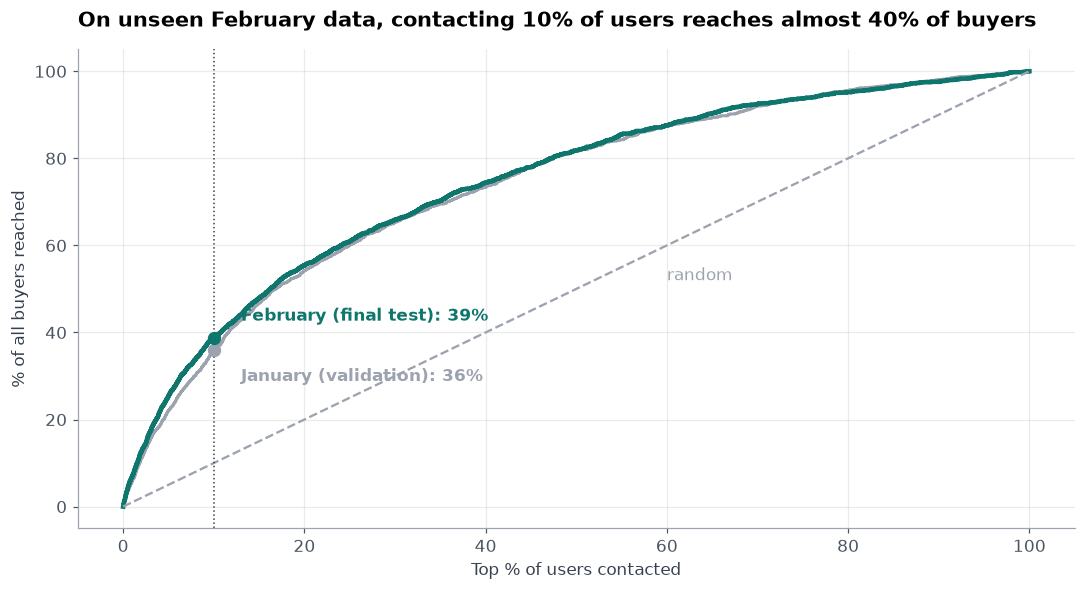

In [97]:
fig, ax = plt.subplots(figsize=(10, 5.5))

# february label above its point, january below, so they don't overlap
offsets = {"January (validation)": -6, "February (final test)": 5}

# gains curve: share of buyers reached when contacting the top users
for probs, labels, color, name in [(valid_probs, y_valid, "#9CA3AF", "January (validation)"), (test_probs, y_test, TEAL, "February (final test)")]:
    order = labels.values[np.argsort(-probs)]
    reached = np.cumsum(order) / order.sum() * 100
    pct = np.arange(1, len(order) + 1) / len(order) * 100
    ax.plot(pct, reached, color=color, linewidth=3 if "February" in name else 2)
    at10 = reached[int(len(order) * 0.10) - 1]
    ax.scatter(10, at10, color=color, s=60, zorder=3)
    ax.text(13, at10 + offsets[name], f"{name}: {at10:.0f}%", color=color, va="center", fontweight="bold")

ax.plot([0, 100], [0, 100], color="#9CA3AF", linestyle="--")
ax.text(60, 52, "random", color="#9CA3AF")
ax.axvline(10, color=DARK, linestyle=":", linewidth=1)
ax.set_xlabel("Top % of users contacted")
ax.set_ylabel("% of all buyers reached")
ax.set_title("On unseen February data, contacting 10% of users reaches almost 40% of buyers", pad=15)

plt.tight_layout()
plt.savefig(fig_path + "final_test_gains.png", bbox_inches="tight")
plt.show()

**Answer:** The February curve sits slightly above January at the top of the ranking. On data the model had never seen, contacting the top 10% of users reached 39% of buyers, compared with 36% on January. The model held up on new data, and even did a little better, probably because the final model was also trained on January, which behaves like February.

## Step 12: Saving the Model

**What is it?** Right now the model only lives in the notebook's memory. If I restart, it's gone. Saving it writes it to a file, so any other program, like the demo, can load it and use it without training again.

**What we save:** the model, the list of features in the exact order it was trained on, the top-10% threshold, and a short record of what the model is and how it scored.
**Why it matters:** this is the bridge between the notebook and a real app. The demo will load these files and make predictions exactly like the notebook does.

In [98]:
import joblib
import json

# a folder for everything the demo needs
model_path = data_path.replace("data/raw/", "models/")
os.makedirs(model_path, exist_ok=True)

# the model itself
joblib.dump(final_model, model_path + "lightgbm_final.pkl")

# the top 10% threshold on February scores
threshold = float(np.quantile(test_probs, 0.90))

# everything the demo needs to use the model the same way
info = {
    "features": feature_cols,
    "threshold_top_10_percent": threshold,
    "trained_on": ["2019-10", "2019-12", "2020-01"],
    "settings": {k: v for k, v in params.items() if k != "verbose"},
    "number_of_trees": int(lgbm_final.best_iteration_),
    "february_pr_auc": round(float(average_precision_score(y_test, test_probs)), 3),
    "february_random_pr_auc": round(float(y_test.mean()), 3)
}
with open(model_path + "model_info.json", "w") as f:
    json.dump(info, f, indent=2)

# check that the saved model gives the same predictions
loaded = joblib.load(model_path + "lightgbm_final.pkl")
print("Same predictions after loading:", np.allclose(loaded.predict_proba(X_test)[:, 1], test_probs))
print("Saved to:", model_path)
print(json.dumps(info, indent=2))

Same predictions after loading: True
Saved to: ../models/
{
  "features": [
    "view",
    "cart",
    "remove_from_cart",
    "past_purchases",
    "sessions",
    "avg_price",
    "views_per_session",
    "remove_per_cart",
    "days_since_last",
    "days_since_first",
    "days_since_last_cart",
    "avg_brand_rate",
    "last_hour",
    "last_weekday"
  ],
  "threshold_top_10_percent": 0.10002270134744783,
  "trained_on": [
    "2019-10",
    "2019-12",
    "2020-01"
  ],
  "settings": {
    "learning_rate": 0.05,
    "num_leaves": 15,
    "min_child_samples": 500,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8
  },
  "number_of_trees": 75,
  "february_pr_auc": 0.158,
  "february_random_pr_auc": 0.043
}


## Step 13: Deployment — Preparing the App Files

**What is it?** Putting the model to work outside the notebook. I'm building a Streamlit app, published for free on Hugging Face Spaces, with three pages: score one user (to see how the model thinks), build a campaign list (rank users and flag the top 10%), and model monitoring.

**Why Streamlit and not a dashboard:** a dashboard only shows results, while an app makes new predictions, which is what shows the model really works. Streamlit is Python only, and anyone can try it from a link.

**What we do here:** gather everything the app needs in one folder: the model in LightGBM's own format (it works across library versions, unlike a pickle file), the model info, a small sample of February users, and realistic feature ranges for the sliders.

In [102]:
app_path = data_path.replace("data/raw/", "app/")
os.makedirs(app_path, exist_ok=True)

# save the model in lightgbm's own format, which works across versions
final_model.booster_.save_model(app_path + "model.txt")

# the model info: features, threshold, settings, scores
with open(app_path + "model_info.json", "w") as f:
    json.dump(info, f, indent=2)

# a small sample of february users for the demo, with their real outcome
sample = test.sample(2000, random_state=42)[["user_id"] + feature_cols + ["target"]]
sample.to_csv(app_path + "sample_users.csv", index=False)

# realistic ranges so the app's sliders don't go to strange values
ranges = full[feature_cols].describe(percentiles=[0.5, 0.99]).T[["min", "50%", "99%"]]
ranges.to_csv(app_path + "feature_ranges.csv")

print(os.listdir(app_path))

['feature_ranges.csv', 'model.txt', 'model_info.json', 'sample_users.csv']
